# Proyecto 2: ETL con Spark, Solr y consultas geoespaciales
## Relación entre la situación económica y la criminalidad en Costa Rica

**Instituto Tecnológico de Costa Rica, Escuela de Computación, sede Alajuela**
**Curso:** Bases de Datos II, II Semestre 2026
**Profesora:** María Auxiliadora Mora

**Integrantes:**
- José David Quirós González
- Carlos Andrés Zúñiga Herrera

## 1. Descripción general del proyecto

### 1.1 Problema de estudio

La criminalidad no se distribuye de forma uniforme en el territorio. Una hipótesis frecuente es que
las condiciones económicas de una zona (desempleo, tipo de actividad productiva, dependencia
económica de los hogares) se relacionan con la cantidad y el tipo de delitos que ocurren en ella.
Este proyecto busca explorar esa relación para los cantones de Costa Rica.

### 1.2 Objetivos

**Objetivo general:** analizar cómo se relacionan los indicadores económicos de los cantones de
Costa Rica con los delitos registrados por el Organismo de Investigación Judicial (OIJ).

**Objetivos específicos:**
1. Construir un pipeline ETL con Apache Spark que extraiga, limpie, impute e integre los delitos
   del OIJ (2019-2026) con los indicadores económicos del Censo 2011 del INEC.
2. Detectar cantones y meses con un comportamiento delictivo anómalo mediante tres algoritmos y
   comparar sus resultados.
3. Indexar el resultado en Apache Solr y desarrollar una aplicación que permita consultar los
   delitos por atributos, por facets y por ubicación geográfica (radio y polígonos).

### 1.3 Justificación

Ninguno de los dos conjuntos de datos responde la pregunta por sí solo: el OIJ dice *dónde y qué*
ocurrió, pero no describe las condiciones de la zona; el censo describe las condiciones económicas,
pero no dice nada de la criminalidad. Al unirlos por cantón es posible, por ejemplo, comparar la
tasa de delitos de los cantones con mayor desempleo contra la de los cantones con menor desempleo,
o ver qué tipos de delito predominan en cantones con economía principalmente agrícola (sector
primario) frente a cantones urbanos de servicios (sector terciario).

## 2. Preparación del ambiente

El notebook está pensado para ejecutarse en **Google Colab**. Los archivos de datos se guardan en
Google Drive, en la carpeta `BD2-Proyecto2/datos`, para que no se pierdan cuando la sesión de
Colab se reinicia.

Se instala PySpark 4.3 porque es compatible con la versión de Java que trae Colab (con PySpark 3.5,
las funciones que pasan datos a pandas, usadas al generar las coordenadas, fallan). La biblioteca `xlrd`
solo se usa para abrir el archivo `.xls` del censo (ver sección 4.2).

In [3]:
import sys

# Se detecta si el notebook corre en Google Colab: el módulo google.colab solo existe ahí.
# Así el mismo notebook funciona tanto en Colab como en una computadora local.
en_colab = "google.colab" in sys.modules

if en_colab:
    # Colab no trae PySpark instalado. Se fija la versión 4.3.0: las versiones 3.x fallan con el Java que trae
    # Colab al pasar datos a pandas (Apache Arrow), que se usa al generar las coordenadas.
    # xlrd es la biblioteca que le permite a pandas abrir archivos .xls (formato antiguo de Excel).
    !pip install -q pyspark==4.3.0 xlrd

In [4]:
import os

if en_colab:
    # Se monta Google Drive como si fuera una carpeta más del sistema de archivos.
    # Así los datos y los resultados quedan guardados aunque la sesión de Colab se reinicie.
    from google.colab import drive
    drive.mount("/content/drive")
    carpeta_proyecto = "/content/drive/MyDrive/BD2-Proyecto2"
else:
    carpeta_proyecto = "."

carpeta_datos = carpeta_proyecto + "/datos"

# Verificación temprana: si la carpeta de datos no existe, se detiene el notebook con un mensaje claro,
# en lugar de fallar más adelante o de crear carpetas vacías por error.
if not os.path.isdir(carpeta_datos):
    raise FileNotFoundError(
        "No se encontró la carpeta de datos: " + carpeta_datos
        + ". Revise que en Drive exista BD2-Proyecto2/datos con los tres archivos."
    )
carpeta_intermedia = carpeta_proyecto + "/intermedio"

# Rutas de los archivos de entrada y de los resultados intermedios.
# Se definen una sola vez aquí para no repetirlas en todo el notebook.
ruta_oij = carpeta_datos + "/Estadisticas.csv"
ruta_censo_xls = carpeta_datos + "/censo2011_empleo.xls"
ruta_censo_csv = carpeta_intermedia + "/censo2011_empleo_crudo.csv"
ruta_cantones = carpeta_datos + "/cantones.geojson"

print("Carpeta de datos:", carpeta_datos)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Carpeta de datos: /content/drive/MyDrive/BD2-Proyecto2/datos


In [5]:
import os
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql import Window
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, ArrayType

# SparkSession es el punto de entrada a Spark: con ella se leen los datos y se crean los DataFrames.
# - appName: nombre con el que aparece la aplicación en la interfaz de Spark.
# - spark.driver.memory: memoria del proceso principal; 4 GB alcanzan para unos 240 mil registros.
# - spark.sql.session.timeZone: zona horaria usada al trabajar con fechas.
spark = (
    SparkSession.builder
    .appName("ProyectoCrimenEconomia")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.session.timeZone", "America/Costa_Rica")
    .getOrCreate()
)

# Solo se muestran los errores en los logs, para que las salidas del notebook queden limpias.
spark.sparkContext.setLogLevel("ERROR")
# Carpeta para resultados intermedios (CSV convertido, Parquet). exist_ok evita un error si ya existe.
os.makedirs(carpeta_intermedia, exist_ok=True)

print("Versión de Spark:", spark.version)

Versión de Spark: 4.3.0


### 2.1 Funciones auxiliares

Los nombres de lugares vienen escritos de forma distinta en cada fuente: con tildes o sin ellas,
en mayúsculas o en minúsculas, con espacios de más o con entidades HTML (por ejemplo `&#201;` en
lugar de `É`). Para poder compararlos se define una función que los lleva todos a una misma forma:
mayúsculas, sin tildes, con la Ñ cambiada por N (el OIJ escribe `CANAS` y el censo `Cañas`) y con un
solo espacio entre palabras. Esta forma normalizada se usa solo como **llave** para comparar y unir;
los valores que se muestran al usuario conservan su escritura.

La función recibe y devuelve una **columna de Spark**, así que la transformación la ejecuta Spark
sobre todos los registros, no Python fila por fila.

In [6]:
# Entidades HTML que aparecen en los datos del OIJ y el carácter que representan.
# Por ejemplo, el sitio exportó "SARCH&#205;" en lugar de "SARCHÍ".
entidades_html = {
    "&#193;": "Á",
    "&#201;": "É",
    "&#205;": "Í",
    "&#211;": "Ó",
    "&#218;": "Ú",
    "&#209;": "Ñ",
    "&#220;": "Ü",
}


# normalizar_texto recibe una columna de Spark y devuelve otra columna transformada.
# No procesa los datos en Python: arma una expresión que Spark ejecuta sobre todos los registros.
# El resultado se usa como LLAVE para comparar nombres entre fuentes, no para mostrarlo.
def normalizar_texto(columna):
    resultado = F.upper(F.trim(columna))
    # Reemplaza cada entidad HTML por su carácter (&#201; → É).
    for entidad in entidades_html:
        resultado = F.regexp_replace(resultado, entidad, entidades_html[entidad])
    # translate cambia cada carácter de la primera cadena por el de la misma posición en la segunda:
    # Á→A, É→E, ..., Ñ→N. Así "CAÑAS" (censo) y "CANAS" (OIJ) quedan iguales.
    resultado = F.translate(resultado, "ÁÉÍÓÚÜÑ", "AEIOUUN")
    resultado = F.regexp_replace(resultado, "\\s+", " ")
    return resultado


# Función de apoyo para la exploración: muestra cuántas veces aparece cada valor de una columna
# y qué porcentaje representa del total. Se usa varias veces, por eso se define una sola vez.
def contar_por_valor(df, columna, cantidad=10):
    total = df.count()
    resultado = (
        df.groupBy(columna)
        .count()
        .withColumn("porcentaje", F.round(F.col("count") / total * 100, 2))
        .orderBy(F.desc("count"))
    )
    resultado.show(cantidad, truncate=False)

## 3. Descripción de los conjuntos de datos

### 3.1 Estadísticas policiales del OIJ

| Característica | Detalle |
|---|---|
| Fuente | Poder Judicial, Organismo de Investigación Judicial. Estadísticas policiales en línea |
| Enlace | https://pjenlinea3.poder-judicial.go.cr/estadisticasoij/ |
| Formato | CSV exportado desde el sitio |
| Periodo | 1 de enero de 2019 al 22 de noviembre de 2026 |
| Granularidad | Un registro por delito denunciado |
| Ubicación | Provincia y cantón (no incluye distrito ni coordenadas) |

Cada registro describe un delito: tipo (`Delito`) y subtipo (`SubDelito`), fecha, franja horaria
de 3 horas, tipo de víctima, edad (por rango), sexo y nacionalidad de la víctima, provincia y
cantón. Los delitos registrados son asalto, hurto, robo, robo de vehículo, tacha de vehículo y
homicidio.

### 3.2 Indicadores económicos del Censo 2011

| Característica | Detalle |
|---|---|
| Fuente | Instituto Nacional de Estadística y Censos (INEC). Censo Nacional de Población y Vivienda 2011, Cuadro 22 |
| Enlace | https://admin.inec.cr/sites/default/files/media/reempleocenso2011-22.xls_2.xls |
| Formato | Excel (`.xls`) con formato de reporte |
| Granularidad | Un registro por país, provincia, cantón y distrito |

Indicadores incluidos: población de 15 años y más, tasa neta de participación, tasa de ocupación,
tasa de desempleo abierto, porcentaje de población económicamente inactiva, relación de
dependencia económica y porcentaje de población ocupada en los sectores primario, secundario y
terciario.

### 3.3 Límites cantonales (dato auxiliar)

| Característica | Detalle |
|---|---|
| Fuente | geoBoundaries, nivel ADM2 (cantones) de Costa Rica |
| Enlace | https://www.geoboundaries.org |
| Formato | GeoJSON |
| Uso | Generar coordenadas dentro del cantón de cada delito |

Ninguno de los dos conjuntos principales trae coordenadas. Siguiendo la indicación del Anexo 1,
se asignan coordenadas aleatorias respetando la ubicación conocida del delito: cada punto se genera
**dentro del polígono real de su cantón**. Para eso se necesita esta capa de límites.

## 4. Extracción

### 4.1 Delitos del OIJ

Antes de leer el archivo como tabla, conviene revisarlo como texto. Al abrirlo se nota que el
encabezado no coincide con el contenido: el encabezado nombra una columna `Distrito`, pero no
nombra la columna de la hora. Si se lee con `header=True`, todos los nombres quedan corridos una
posición (la columna llamada `Victima` contendría la hora, la llamada `Distrito` contendría el
cantón, etc.).

In [7]:
# spark.read.text lee el archivo como texto plano: una fila por línea, en una sola columna "value".
# Sirve para revisar el archivo "en crudo" antes de interpretarlo como CSV.
lineas_oij = spark.read.text(ruta_oij)

print("Encabezado del archivo:")
print(lineas_oij.first()["value"])
print()
print("Primera línea de datos:")
print(lineas_oij.take(2)[1]["value"])

Encabezado del archivo:
Delito,SubDelito,Fecha,Victima,SubVictima,Edad,Sexo,Nacionalidad,Provincia,Canton,Distrito,

Primera línea de datos:
ASALTO,ARMA BLANCA,2019-01-01,06:00:00 - 08:59:59,PERSONA,PEATON [PERSONA],Mayor de edad,HOMBRE,COSTA RICA,SAN JOSE,ESCAZU,


Se cuenta cuántos campos tiene cada línea (separando por comas). El encabezado tiene 11 nombres más
una coma al final, y las líneas de datos tienen 11 valores más una coma al final; es decir, la
columna que falta en el encabezado (la hora) está compensada por la columna `Distrito`, que en
realidad no existe en los datos.

Además aparecen unas pocas líneas con **13 campos**: tienen una coma de más dentro de un valor.

In [8]:
# F.split separa cada línea por comas y F.size cuenta cuántas partes quedaron.
# Luego se agrupa por esa cantidad para ver si todas las líneas tienen la misma estructura.
conteo_campos = (
    lineas_oij
    .withColumn("cantidad_campos", F.size(F.split(F.col("value"), ",")))
    .groupBy("cantidad_campos")
    .count()
    .orderBy("cantidad_campos")
)

conteo_campos.show()

+---------------+------+
|cantidad_campos| count|
+---------------+------+
|             12|241490|
|             13|     9|
+---------------+------+



Por esto el archivo se lee con un **esquema definido manualmente**, ignorando el encabezado
original. Todas las columnas se leen como texto: los tipos correctos (por ejemplo, fecha) se asignan
en la etapa de limpieza, después de validar los valores.

La columna `columna_sobrante` debería venir vacía. Solo tiene valor en las líneas con una coma de
más, y sirve para detectarlas.

In [9]:
# Esquema manual: nombre y tipo de cada columna en el orden REAL de los datos,
# porque el encabezado del archivo está corrido (le falta "Hora" y sobra "Distrito").
# Todo se lee como StringType (texto); los tipos correctos se asignan en la limpieza.
esquema_oij = StructType([
    StructField("delito", StringType(), True),
    StructField("subdelito", StringType(), True),
    StructField("fecha", StringType(), True),
    StructField("hora", StringType(), True),
    StructField("victima", StringType(), True),
    StructField("subvictima", StringType(), True),
    StructField("edad", StringType(), True),
    StructField("sexo", StringType(), True),
    StructField("nacionalidad", StringType(), True),
    StructField("provincia", StringType(), True),
    StructField("canton", StringType(), True),
    # Columna extra: solo tiene valor en las líneas con una coma de más. Sirve para detectarlas.
    StructField("columna_sobrante", StringType(), True),
])

# header=True hace que Spark salte la primera línea (el encabezado incorrecto),
# y .schema(...) le indica que use nuestros nombres en lugar de los del archivo.
oij_crudo = (
    spark.read
    .option("header", True)
    .option("encoding", "UTF-8")
    .schema(esquema_oij)
    .csv(ruta_oij)
)

# cache() guarda el DataFrame en memoria después de la primera lectura.
# Como se consulta muchas veces en la exploración, evita leer el CSV de nuevo cada vez.
oij_crudo.cache()

print("Cantidad de registros:", oij_crudo.count())
print("Cantidad de columnas:", len(oij_crudo.columns))
oij_crudo.printSchema()

Cantidad de registros: 241498
Cantidad de columnas: 12
root
 |-- delito: string (nullable = true)
 |-- subdelito: string (nullable = true)
 |-- fecha: string (nullable = true)
 |-- hora: string (nullable = true)
 |-- victima: string (nullable = true)
 |-- subvictima: string (nullable = true)
 |-- edad: string (nullable = true)
 |-- sexo: string (nullable = true)
 |-- nacionalidad: string (nullable = true)
 |-- provincia: string (nullable = true)
 |-- canton: string (nullable = true)
 |-- columna_sobrante: string (nullable = true)



In [10]:
oij_crudo.show(5, truncate=False)

+------+-----------+----------+-------------------+--------+-------------------------------------------------------+-------------+------+------------+---------+--------+----------------+
|delito|subdelito  |fecha     |hora               |victima |subvictima                                             |edad         |sexo  |nacionalidad|provincia|canton  |columna_sobrante|
+------+-----------+----------+-------------------+--------+-------------------------------------------------------+-------------+------+------------+---------+--------+----------------+
|ASALTO|ARMA BLANCA|2019-01-01|06:00:00 - 08:59:59|PERSONA |PEATON [PERSONA]                                       |Mayor de edad|HOMBRE|COSTA RICA  |SAN JOSE |ESCAZU  |NULL            |
|ASALTO|ARMA BLANCA|2019-01-06|18:00:00 - 20:59:59|PERSONA |OTRO O INDETERMINADO [PERSONA]                         |Mayor de edad|HOMBRE|COSTA RICA  |SAN JOSE |SAN JOSE|NULL            |
|ASALTO|ARMA BLANCA|2019-01-07|09:00:00 - 11:59:59|PERSONA |PEATO

### 4.2 Indicadores económicos del Censo 2011

Spark no tiene un lector nativo para archivos de Excel. Por eso el único paso fuera de Spark es una
**conversión de formato**: pandas abre el `.xls` y lo guarda tal cual como CSV, sin modificar ni
filtrar ningún valor. A partir de ahí, toda la lectura y el procesamiento se hacen con Spark.

In [11]:
# Conversión de formato, el único paso fuera de Spark: Spark no lee archivos de Excel de forma nativa.
# - header=None: ninguna fila se interpreta como encabezado.
# - dtype=str: todo se lee como texto, para no alterar ningún valor al convertir.
censo_excel = pd.read_excel(ruta_censo_xls, header=None, dtype=str)
censo_excel.to_csv(ruta_censo_csv, index=False, header=False)

print("Archivo convertido:", ruta_censo_csv)

Archivo convertido: /content/drive/MyDrive/BD2-Proyecto2/intermedio/censo2011_empleo_crudo.csv


El archivo tiene **formato de reporte**, no de tabla:

- Las primeras filas son el título y los encabezados (que ocupan dos filas).
- Una misma columna (`Provincia, cantón y distrito`) mezcla los tres niveles geográficos.
- El nivel de cada fila no está escrito en ninguna parte: se deduce de su posición. Las filas de
  provincia y de cantón están rodeadas por filas vacías; las de distrito aparecen seguidas una
  tras otra, y sus nombres vienen rellenados con espacios al final.

Algunas celdas del encabezado tienen saltos de línea dentro del texto (por ejemplo
`Sector
Primario`), por eso se lee con la opción `multiLine`; sin ella, Spark parte esas celdas
en filas de más y la numeración queda corrida.

Como la jerarquía depende del **orden de las filas**, al leer el archivo se le agrega a cada fila
su número de línea. El archivo es pequeño y Spark lo lee en una sola partición, así que
`monotonically_increasing_id` produce números consecutivos en el mismo orden del archivo.

In [12]:
# Lectura del CSV convertido con Spark:
# - multiLine: algunas celdas del encabezado tienen saltos de línea dentro del texto.
# - coalesce(1): todo queda en una sola partición, para conservar el orden original de las filas.
# - monotonically_increasing_id: asigna a cada fila un número creciente. Con una sola partición,
#   ese número es el número de línea del archivo, que se necesita para deducir la jerarquía.
censo_texto = (
    spark.read
    .option("header", False)
    .option("multiLine", True)
    .csv(ruta_censo_csv)
    .coalesce(1)
    .withColumn("fila", F.monotonically_increasing_id())
)

# Spark nombra las columnas sin encabezado como _c0, _c1, _c2...
# Se reemplazan por nombres descriptivos, en el mismo orden de las columnas del Excel.
nombres_columnas_censo = [
    "vacia",
    "nombre_original",
    "poblacion_15_mas",
    "tasa_participacion",
    "tasa_ocupacion",
    "tasa_desempleo",
    "pct_inactiva",
    "relacion_dependencia",
    "pct_sector_primario",
    "pct_sector_secundario",
    "pct_sector_terciario",
]

# Recorre la lista y renombra: _c0 → vacia, _c1 → nombre_original, etc.
for posicion in range(len(nombres_columnas_censo)):
    censo_texto = censo_texto.withColumnRenamed("_c" + str(posicion), nombres_columnas_censo[posicion])

# La primera columna del Excel está vacía (es un margen del reporte), así que se elimina.
censo_texto = censo_texto.drop("vacia")

print("Filas en el archivo:", censo_texto.count())
censo_texto.orderBy("fila").show(22, truncate=False)

Filas en el archivo: 738
+----------------------------------------------------------------------+--------------------------+--------------------------+------------------+-------------------------+-----------------------------------------------+---------------------------------+---------------------------------+---------------------+--------------------+----+
|nombre_original                                                       |poblacion_15_mas          |tasa_participacion        |tasa_ocupacion    |tasa_desempleo           |pct_inactiva                                   |relacion_dependencia             |pct_sector_primario              |pct_sector_secundario|pct_sector_terciario|fila|
+----------------------------------------------------------------------+--------------------------+--------------------------+------------------+-------------------------+-----------------------------------------------+---------------------------------+---------------------------------+----------------

Para identificar el nivel de cada fila se usan **funciones de ventana** (`lag` y `lead`), que
permiten mirar la fila anterior y la siguiente:

1. Una fila es un **agregado** (país, provincia o cantón) si la fila anterior y la siguiente están
   vacías y su nombre no termina en espacios.
2. Un agregado es **provincia** si su nombre es una de las siete provincias y el siguiente agregado
   viene justo dos filas después (el primer cantón de la provincia).
3. El agregado `Costa Rica` es el total del **país**.
4. Los demás agregados son **cantones**, y las demás filas con nombre son **distritos**.

Luego, con `last(..., ignorenulls=True)` se arrastra hacia abajo el nombre de la provincia y del
cantón, para que cada fila sepa a qué provincia y cantón pertenece.

In [13]:
# Lista de provincias: permite distinguir una fila de provincia de una fila de cantón con el mismo
# nombre (por ejemplo, la provincia San José y el cantón San José).
nombres_provincias = ["San José", "Alajuela", "Cartago", "Heredia", "Guanacaste", "Puntarenas", "Limón"]

# Window define una "ventana": un orden sobre las filas que permite consultar filas vecinas.
# - ventana_filas: ordena por número de fila; se usa con lag (fila anterior) y lead (fila siguiente).
# - ventana_acumulada: desde la primera fila hasta la actual; se usa para arrastrar valores hacia abajo.
ventana_filas = Window.orderBy("fila")
ventana_acumulada = Window.orderBy("fila").rowsBetween(Window.unboundedPreceding, 0)

# Paso 1: columnas auxiliares para cada fila.
# - filter(fila >= 8): descarta el título y los encabezados del reporte.
# - lag / lead: revisan si la fila anterior o la siguiente están vacías.
# - termina_en_espacios: los nombres de distrito vienen rellenados con espacios a la derecha.
# - es_agregado: fila de país, provincia o cantón (entre filas vacías y sin espacios al final).
censo_filas = (
    censo_texto
    .filter(F.col("fila") >= 8)
    .withColumn("anterior_vacia", F.lag("nombre_original", 1).over(ventana_filas).isNull())
    .withColumn("siguiente_vacia", F.lead("nombre_original", 1).over(ventana_filas).isNull())
    .withColumn("termina_en_espacios", F.col("nombre_original") != F.rtrim(F.col("nombre_original")))
    .withColumn(
        "es_agregado",
        F.col("nombre_original").isNotNull()
        & F.col("anterior_vacia")
        & F.col("siguiente_vacia")
        & ~F.col("termina_en_espacios"),
    )
    # Revisa si la fila que está dos posiciones más abajo también es un agregado.
    # Una provincia siempre va seguida (dos filas después) por su primer cantón, que también es agregado.
    .withColumn("agregado_dos_filas_despues", F.lead("es_agregado", 2).over(ventana_filas))
    .withColumn("nombre", F.trim(F.col("nombre_original")))
)

# Paso 2: se asigna el nivel de cada fila con una cadena when / otherwise,
# que funciona como un if / elif / else que Spark evalúa en cada fila.
censo_filas = censo_filas.withColumn(
    "nivel",
    F.when(F.col("nombre").isNull(), F.lit(None))
    .when(F.col("es_agregado") & (F.col("nombre") == "Costa Rica"), "pais")
    .when(
        F.col("es_agregado")
        & F.col("nombre").isin(nombres_provincias)
        & F.coalesce(F.col("agregado_dos_filas_despues"), F.lit(False)),
        "provincia",
    )
    .when(F.col("es_agregado"), "canton")
    .otherwise("distrito"),
)

# Paso 3: se "arrastra" hacia abajo el nombre de la provincia y del cantón.
# last(..., ignorenulls=True) sobre la ventana acumulada devuelve el último valor no nulo visto
# hasta esa fila; así cada distrito sabe a qué cantón y provincia pertenece.
censo_filas = (
    censo_filas
    .filter(F.col("nivel").isNotNull())
    .withColumn("nombre_provincia", F.when(F.col("nivel") == "provincia", F.col("nombre")))
    .withColumn("nombre_canton", F.when(F.col("nivel") == "canton", F.col("nombre")))
    .withColumn("provincia", F.last("nombre_provincia", ignorenulls=True).over(ventana_acumulada))
    .withColumn("canton", F.last("nombre_canton", ignorenulls=True).over(ventana_acumulada))
)

censo_filas.groupBy("nivel").count().orderBy("count").show()

+---------+-----+
|    nivel|count|
+---------+-----+
|provincia|    7|
|   canton|   81|
| distrito|  473|
+---------+-----+



El resultado coincide con la división territorial de 2011: 7 provincias, 81 cantones y 473
distritos. Para el proyecto se usa el **nivel de cantón**, porque es el nivel más fino disponible
en los datos del OIJ.

A continuación se separan las filas de cantón y se convierten los indicadores a números.

In [14]:
# Columnas numéricas del censo. Vienen como texto y se convierten a número.
columnas_indicadores = [
    "poblacion_15_mas",
    "tasa_participacion",
    "tasa_ocupacion",
    "tasa_desempleo",
    "pct_inactiva",
    "relacion_dependencia",
    "pct_sector_primario",
    "pct_sector_secundario",
    "pct_sector_terciario",
]

# Se conservan solo las filas de cantón, que es el nivel que se une con el OIJ.
censo_cantones = censo_filas.filter(F.col("nivel") == "canton").select("provincia", "canton", *columnas_indicadores)

for columna in columnas_indicadores:
    # cast("double") convierte el texto a número decimal; un valor no numérico quedaría nulo.
    censo_cantones = censo_cantones.withColumn(columna, F.col(columna).cast("double"))

# La población es una cantidad de personas, así que se guarda como entero.
censo_cantones = censo_cantones.withColumn("poblacion_15_mas", F.col("poblacion_15_mas").cast("int"))

censo_cantones.cache()

print("Cantones:", censo_cantones.count())
print("Columnas:", len(censo_cantones.columns))
censo_cantones.printSchema()
censo_cantones.show(5, truncate=False)

Cantones: 81
Columnas: 11
root
 |-- provincia: string (nullable = true)
 |-- canton: string (nullable = true)
 |-- poblacion_15_mas: integer (nullable = true)
 |-- tasa_participacion: double (nullable = true)
 |-- tasa_ocupacion: double (nullable = true)
 |-- tasa_desempleo: double (nullable = true)
 |-- pct_inactiva: double (nullable = true)
 |-- relacion_dependencia: double (nullable = true)
 |-- pct_sector_primario: double (nullable = true)
 |-- pct_sector_secundario: double (nullable = true)
 |-- pct_sector_terciario: double (nullable = true)

+---------+------------+----------------+------------------+------------------+------------------+------------------+--------------------+-------------------+---------------------+--------------------+
|provincia|canton      |poblacion_15_mas|tasa_participacion|tasa_ocupacion    |tasa_desempleo    |pct_inactiva      |relacion_dependencia|pct_sector_primario|pct_sector_secundario|pct_sector_terciario|
+---------+------------+----------------+-

### 4.3 Límites cantonales

El GeoJSON es un solo objeto JSON con una lista de `features`, una por cantón. Se lee con la opción
`multiLine` y se usa `explode` para obtener una fila por cantón. En esta etapa solo interesa
revisar qué cantones contiene; las geometrías se usan al generar las coordenadas.

Se le da a Spark un **esquema explícito** con solo los dos campos necesarios (nombre y tipo de
geometría). Sin esquema, Spark recorre todo el archivo para inferir los tipos, incluidas las miles
de coordenadas de los polígonos: en las pruebas, la lectura bajó de unos 21 segundos (o varios
minutos en Colab leyendo desde Drive) a menos de un segundo.

In [15]:
# Esquema con solo los campos que se necesitan: features → properties.shapeName y geometry.type.
# Spark ignora el resto (las coordenadas), así no tiene que recorrer todo el archivo para inferir tipos.
esquema_geojson = StructType([
    StructField("features", ArrayType(StructType([
        StructField("properties", StructType([StructField("shapeName", StringType(), True)]), True),
        StructField("geometry", StructType([StructField("type", StringType(), True)]), True),
    ])), True),
])

# multiLine=True: el GeoJSON es un único objeto JSON repartido en muchas líneas
# (por defecto Spark espera un objeto JSON por línea).
cantones_geo_crudo = spark.read.option("multiLine", True).schema(esquema_geojson).json(ruta_cantones)

# explode convierte la lista "features" en filas: una fila por cantón.
# Luego se extraen el nombre (properties.shapeName) y el tipo de geometría.
cantones_geo = (
    cantones_geo_crudo
    .select(F.explode("features").alias("feature"))
    .select(
        F.col("feature.properties.shapeName").alias("canton"),
        F.col("feature.geometry.type").alias("tipo_geometria"),
    )
)

cantones_geo.cache()

print("Cantones en el GeoJSON:", cantones_geo.count())
cantones_geo.groupBy("tipo_geometria").count().show()

Cantones en el GeoJSON: 83
+--------------+-----+
|tipo_geometria|count|
+--------------+-----+
|       Polygon|   73|
|  MultiPolygon|   10|
+--------------+-----+



## 5. Exploración inicial

### 5.1 Delitos del OIJ

#### Valores faltantes

En este archivo los valores faltantes casi nunca aparecen como celdas vacías: el OIJ los registra
como el texto `Desconocido`. Por eso se cuentan las dos cosas por separado.

In [16]:
# Columnas originales del OIJ que se revisan en la exploración.
columnas_oij = [
    "delito", "subdelito", "fecha", "hora", "victima", "subvictima",
    "edad", "sexo", "nacionalidad", "provincia", "canton",
]

total_oij = oij_crudo.count()
# Para cada columna se cuentan dos tipos de faltante:
# - nulos o vacíos: celdas sin valor.
# - "DESCONOCIDO": el texto que usa el OIJ cuando no tiene el dato.
# Los resultados se acumulan en una lista y al final se convierten en un DataFrame para mostrarlos.
filas_faltantes = []

for columna in columnas_oij:
    nulos = oij_crudo.filter(F.col(columna).isNull() | (F.trim(F.col(columna)) == "")).count()
    desconocidos = oij_crudo.filter(F.upper(F.trim(F.col(columna))) == "DESCONOCIDO").count()
    porcentaje = round((nulos + desconocidos) / total_oij * 100, 2)
    filas_faltantes.append((columna, nulos, desconocidos, porcentaje))

faltantes_oij = spark.createDataFrame(filas_faltantes, ["columna", "nulos", "desconocidos", "porcentaje_faltante"])
faltantes_oij.show(truncate=False)

+------------+-----+------------+-------------------+
|columna     |nulos|desconocidos|porcentaje_faltante|
+------------+-----+------------+-------------------+
|delito      |0    |0           |0.0                |
|subdelito   |0    |190         |0.08               |
|fecha       |0    |0           |0.0                |
|hora        |0    |0           |0.0                |
|victima     |0    |0           |0.0                |
|subvictima  |0    |0           |0.0                |
|edad        |0    |14359       |5.95               |
|sexo        |0    |15213       |6.3                |
|nacionalidad|0    |10359       |4.29               |
|provincia   |0    |24          |0.01               |
|canton      |0    |815         |0.34               |
+------------+-----+------------+-------------------+



#### Cardinalidad de las columnas

La cantidad de valores distintos indica qué tipo de variable es cada columna: las de pocos valores
(`delito`, `victima`, `edad`, `sexo`) son categóricas de baja cardinalidad; `nacionalidad` y
`canton` tienen más valores.

In [17]:
# distinct().count() cuenta cuántos valores diferentes tiene cada columna (su cardinalidad).
filas_cardinalidad = []

for columna in columnas_oij:
    distintos = oij_crudo.select(columna).distinct().count()
    filas_cardinalidad.append((columna, distintos))

spark.createDataFrame(filas_cardinalidad, ["columna", "valores_distintos"]).show(truncate=False)

+------------+-----------------+
|columna     |valores_distintos|
+------------+-----------------+
|delito      |6                |
|subdelito   |40               |
|fecha       |2883             |
|hora        |8                |
|victima     |3                |
|subvictima  |56               |
|edad        |4                |
|sexo        |3                |
|nacionalidad|133              |
|provincia   |10               |
|canton      |85               |
+------------+-----------------+



#### Distribución de las variables categóricas

In [18]:
# Distribución de las variables categóricas con pocos valores.
for columna in ["delito", "victima", "edad", "sexo", "provincia"]:
    print("Columna:", columna)
    contar_por_valor(oij_crudo, columna)

Columna: delito
+-----------------+-----+----------+
|delito           |count|porcentaje|
+-----------------+-----+----------+
|ASALTO           |80399|33.29     |
|HURTO            |78539|32.52     |
|ROBO DE VEHICULO |35378|14.65     |
|TACHA DE VEHICULO|30293|12.54     |
|ROBO             |11159|4.62      |
|HOMICIDIO        |5730 |2.37      |
+-----------------+-----+----------+

Columna: victima
+--------+------+----------+
|victima |count |porcentaje|
+--------+------+----------+
|PERSONA |140607|58.22     |
|VEHICULO|85168 |35.27     |
|OTROS   |15723 |6.51      |
+--------+------+----------+

Columna: edad
+-------------+------+----------+
|edad         |count |porcentaje|
+-------------+------+----------+
|Mayor de edad|206546|85.53     |
|Desconocido  |14359 |5.95      |
|Adulto Mayor |11872 |4.92      |
|Menor de edad|8721  |3.61      |
+-------------+------+----------+

Columna: sexo
+-----------+------+----------+
|sexo       |count |porcentaje|
+-----------+------+-------

En `subdelito` aparecen dos etiquetas para el mismo concepto: `POR DESCUIDO` y `DESCUIDO`. También
hay subdelitos cuyo nombre repite el del delito (por ejemplo, `TACHA DE VEHICULO`).

In [19]:
(
    oij_crudo
    # Se agrupan delito y subdelito juntos para ver qué subtipos tiene cada delito.
    .groupBy("delito", "subdelito")
    .count()
    .orderBy("delito", F.desc("count"))
    .show(50, truncate=False)
)

+-----------------+------------------------------+-----+
|delito           |subdelito                     |count|
+-----------------+------------------------------+-----+
|ASALTO           |ARMA DE FUEGO                 |30517|
|ASALTO           |ARMA BLANCA                   |19498|
|ASALTO           |ARREBATO                      |12419|
|ASALTO           |GOLPES                        |7665 |
|ASALTO           |INTIMIDACION VERBAL           |3995 |
|ASALTO           |CANDADO CHINO                 |2470 |
|ASALTO           |INMOVILIZACION                |1974 |
|ASALTO           |ARMA CONTUNDENTE              |988  |
|ASALTO           |OTRO O INDETERMINADO          |748  |
|ASALTO           |USO DE GAS                    |74   |
|ASALTO           |DESCONOCIDO                   |51   |
|HOMICIDIO        |AJUSTE DE CUENTAS/VENGANZA    |3577 |
|HOMICIDIO        |DISCUSION/RI&#209;A           |839  |
|HOMICIDIO        |POR LA COMISION DE OTRO DELITO|538  |
|HOMICIDIO        |OTRO O INDET

#### Fechas y franjas horarias

La fecha viene en formato `yyyy-MM-dd`. Se convierte de forma temporal (sin modificar el
DataFrame) para calcular el rango y los registros por año. El año 2026 está incompleto: los datos
llegan hasta noviembre.

Fechas que no se pudieron convertir: 0
+------------+------------+
|fecha_minima|fecha_maxima|
+------------+------------+
|  2019-01-01|  2026-11-22|
+------------+------------+



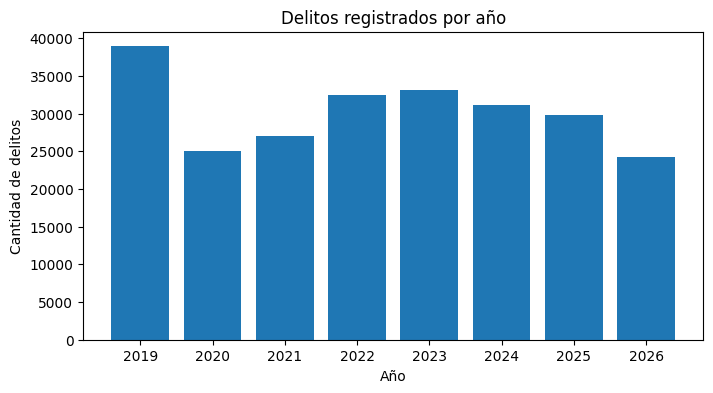

In [20]:
# to_date convierte el texto a fecha con el formato indicado; si no calza, devuelve nulo.
# Se guarda en una variable temporal: oij_crudo no se modifica durante la exploración.
fechas = oij_crudo.withColumn("fecha_convertida", F.to_date("fecha", "yyyy-MM-dd"))

print("Fechas que no se pudieron convertir:", fechas.filter(F.col("fecha_convertida").isNull()).count())
fechas.select(F.min("fecha_convertida").alias("fecha_minima"), F.max("fecha_convertida").alias("fecha_maxima")).show()

# Se agrupa por año, se cuenta y se pasa a pandas (toPandas) solo para graficar.
# El resultado son 8 filas, así que traerlo a Python no tiene costo.
delitos_por_anio = (
    fechas
    .groupBy(F.year("fecha_convertida").alias("anio"))
    .count()
    .orderBy("anio")
    .toPandas()
)

plt.figure(figsize=(8, 4))
plt.bar(delitos_por_anio["anio"].astype(str), delitos_por_anio["count"])
plt.title("Delitos registrados por año")
plt.xlabel("Año")
plt.ylabel("Cantidad de delitos")
plt.show()

El gráfico muestra una caída fuerte en 2020, que coincide con las restricciones de movilidad por
la pandemia de COVID-19, y una recuperación a partir de 2022. La barra de 2026 es menor porque el
año no está completo.

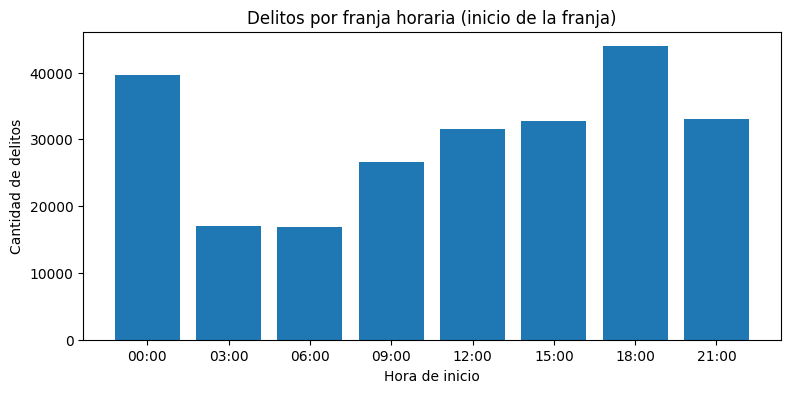

In [21]:
# Más abajo, str.slice(0, 5) toma solo la hora de inicio ("06:00") para que las etiquetas sean cortas.
delitos_por_hora = oij_crudo.groupBy("hora").count().orderBy("hora").toPandas()

plt.figure(figsize=(9, 4))
plt.bar(delitos_por_hora["hora"].str.slice(0, 5), delitos_por_hora["count"])
plt.title("Delitos por franja horaria (inicio de la franja)")
plt.xlabel("Hora de inicio")
plt.ylabel("Cantidad de delitos")
plt.show()

#### Estadísticas descriptivas

Las columnas del OIJ son categóricas, así que las estadísticas numéricas se calculan sobre
**conteos**: cuántos delitos ocurren por día y cuántos por cantón. Estas distribuciones también
sirven para una primera revisión de valores atípicos.

In [22]:
# Conteos por día y por cantón. Sobre ellos se calculan estadísticas descriptivas,
# porque las columnas originales son categóricas y no tienen media ni desviación.
delitos_por_dia = oij_crudo.groupBy("fecha").count().withColumnRenamed("count", "delitos_dia")
delitos_por_canton = oij_crudo.groupBy("canton").count().withColumnRenamed("count", "delitos_canton")

delitos_por_dia.describe("delitos_dia").show()
delitos_por_canton.describe("delitos_canton").show()

print("Cantones con más delitos:")
delitos_por_canton.orderBy(F.desc("delitos_canton")).show(5)
print("Cantones con menos delitos:")
delitos_por_canton.orderBy("delitos_canton").show(5)

+-------+------------------+
|summary|       delitos_dia|
+-------+------------------+
|  count|              2883|
|   mean| 83.76621574748526|
| stddev|19.933272006838592|
|    min|                19|
|    max|               188|
+-------+------------------+

+-------+------------------+
|summary|    delitos_canton|
+-------+------------------+
|  count|                85|
|   mean|2841.1529411764704|
| stddev| 6508.578080586607|
|    min|               109|
|    max|             57595|
+-------+------------------+

Cantones con más delitos:
+----------+--------------+
|    canton|delitos_canton|
+----------+--------------+
|  SAN JOSE|         57595|
|  ALAJUELA|         15439|
|   HEREDIA|          9806|
|PUNTARENAS|          7781|
|   CARTAGO|          7418|
+----------+--------------+
only showing top 5 rows
Cantones con menos delitos:
+----------+--------------+
|    canton|delitos_canton|
+----------+--------------+
|TURRUBARES|           109|
| NANDAYURE|           129|
|     

La diferencia entre cantones es enorme (de un centenar a decenas de miles de delitos), pero esto
se debe sobre todo a la **población**: San José concentra mucha gente. Por eso, después del join,
se calcula una tasa de delitos por habitante, que sí permite comparar cantones de distinto tamaño.

#### Registros duplicados

In [23]:
# distinct() elimina las filas idénticas en todas sus columnas; la diferencia con el total
# es la cantidad de registros repetidos.
distintos_oij = oij_crudo.distinct().count()
print("Registros totales:", total_oij)
print("Registros distintos:", distintos_oij)
print("Registros repetidos:", total_oij - distintos_oij)

Registros totales: 241498
Registros distintos: 228981
Registros repetidos: 12517


Hay registros idénticos en todas sus columnas. Sin embargo, el archivo **no trae un identificador
del caso**, y los valores son bastante generales (fecha, franja de tres horas, cantón, rango de
edad). Dos hurtos distintos a dos hombres adultos costarricenses, en el mismo cantón, el mismo día y
en la misma franja, producen dos filas idénticas. La decisión sobre estos registros se justifica en
la etapa de limpieza.

#### Problemas de formato en los nombres

Se revisan las líneas con una coma de más (las que tienen valor en `columna_sobrante`) y los
nombres de cantón que contienen entidades HTML.

In [24]:
# Registros con valor en columna_sobrante (líneas desplazadas) y cantones con entidades HTML.
print("Líneas con una coma de más:")
oij_crudo.filter(F.col("columna_sobrante").isNotNull()).select(
    "fecha", "nacionalidad", "provincia", "canton", "columna_sobrante"
).show(truncate=False)

print("Cantones con entidades HTML:")
oij_crudo.filter(F.col("canton").contains("&#")).groupBy("canton").count().show(truncate=False)

Líneas con una coma de más:
+----------+------------------------------+-----------+----------+----------------+
|fecha     |nacionalidad                  |provincia  |canton    |columna_sobrante|
+----------+------------------------------+-----------+----------+----------------+
|2023-02-09|VIRGENES BRITANICAS           | ISLAS     |PUNTARENAS|OSA             |
|2022-02-22|VIRGENES BRITANICAS           | ISLAS     |PUNTARENAS|QUEPOS          |
|2021-04-22|VIRGENES DE LOS ESTADOS UNIDOS| ISLAS     |PUNTARENAS|MONTEVERDE      |
|2021-08-21|VIRGENES BRITANICAS           | ISLAS     |PUNTARENAS|OSA             |
|2022-03-16|VIRGENES BRITANICAS           | ISLAS     |PUNTARENAS|OSA             |
|2025-09-14|MALVINAS                      | ISLAS     |SAN JOSE  |SAN JOSE        |
|2025-10-01|VATICANO                      | CIUDAD DEL|PUNTARENAS|OSA             |
|2025-10-12|VATICANO                      | CIUDAD DEL|HEREDIA   |HEREDIA         |
|2024-03-02|VIRGENES BRITANICAS           | ISLA

En las líneas desplazadas, la nacionalidad está escrita como `VIRGENES BRITANICAS, ISLAS` sin
comillas, así que la coma la parte en dos columnas y todo lo que sigue queda corrido: la provincia
queda en `canton` y el cantón en `columna_sobrante`.

### 5.2 Indicadores del Censo 2011

#### Estadísticas descriptivas y valores faltantes

In [25]:
# describe() calcula cantidad, media, desviación estándar, mínimo y máximo de cada columna.
# Se divide en dos llamadas solo para que las tablas quepan en pantalla.
censo_cantones.select(
    "poblacion_15_mas", "tasa_participacion", "tasa_ocupacion", "tasa_desempleo", "pct_inactiva"
).describe().show()

censo_cantones.select(
    "relacion_dependencia", "pct_sector_primario", "pct_sector_secundario", "pct_sector_terciario"
).describe().show()

+-------+------------------+------------------+------------------+------------------+------------------+
|summary|  poblacion_15_mas|tasa_participacion|    tasa_ocupacion|    tasa_desempleo|      pct_inactiva|
+-------+------------------+------------------+------------------+------------------+------------------+
|  count|                81|                81|                81|                81|                81|
|   mean| 39924.46913580247| 51.98671929210541|50.329827659857955|3.1989544207841423| 48.01328070789458|
| stddev|39873.735780299794| 4.828274589750618| 4.759854129622025| 0.797313194642913| 4.828274589750618|
|    min|              4133| 42.17557251908397| 40.30295801526718|0.9072978303747534|38.224485510289796|
|    max|            225856|61.775514489710204| 60.36329273414531| 5.646054088249248| 57.82442748091603|
+-------+------------------+------------------+------------------+------------------+------------------+

+-------+--------------------+-------------------+----

In [26]:
# Conteo de nulos por columna del censo; debería ser cero si la lectura del reporte quedó bien.
filas_nulos_censo = []

for columna in censo_cantones.columns:
    nulos = censo_cantones.filter(F.col(columna).isNull()).count()
    filas_nulos_censo.append((columna, nulos))

spark.createDataFrame(filas_nulos_censo, ["columna", "nulos"]).show(truncate=False)

+---------------------+-----+
|columna              |nulos|
+---------------------+-----+
|provincia            |0    |
|canton               |0    |
|poblacion_15_mas     |0    |
|tasa_participacion   |0    |
|tasa_ocupacion       |0    |
|tasa_desempleo       |0    |
|pct_inactiva         |0    |
|relacion_dependencia |0    |
|pct_sector_primario  |0    |
|pct_sector_secundario|0    |
|pct_sector_terciario |0    |
+---------------------+-----+



#### Consistencia interna

Algunos indicadores están relacionados por definición, y eso permite validar que la lectura del
reporte quedó bien hecha:

- La tasa neta de participación y el porcentaje de población inactiva son complementarios: deben
  sumar 100.
- Los porcentajes de población ocupada en los tres sectores deben sumar 100.

In [27]:
# Validación con reglas del dominio: participación + inactiva = 100, y la suma de los tres sectores = 100.
# Si el mínimo y el máximo de ambas sumas dan 100, la lectura del reporte es correcta.
validacion_censo = (
    censo_cantones
    .withColumn("suma_participacion_inactiva", F.round(F.col("tasa_participacion") + F.col("pct_inactiva"), 4))
    .withColumn(
        "suma_sectores",
        F.round(F.col("pct_sector_primario") + F.col("pct_sector_secundario") + F.col("pct_sector_terciario"), 4),
    )
)

validacion_censo.select(
    F.min("suma_participacion_inactiva"),
    F.max("suma_participacion_inactiva"),
    F.min("suma_sectores"),
    F.max("suma_sectores"),
).show()

+--------------------------------+--------------------------------+------------------+------------------+
|min(suma_participacion_inactiva)|max(suma_participacion_inactiva)|min(suma_sectores)|max(suma_sectores)|
+--------------------------------+--------------------------------+------------------+------------------+
|                           100.0|                           100.0|             100.0|             100.0|
+--------------------------------+--------------------------------+------------------+------------------+



#### Distribución de los indicadores principales

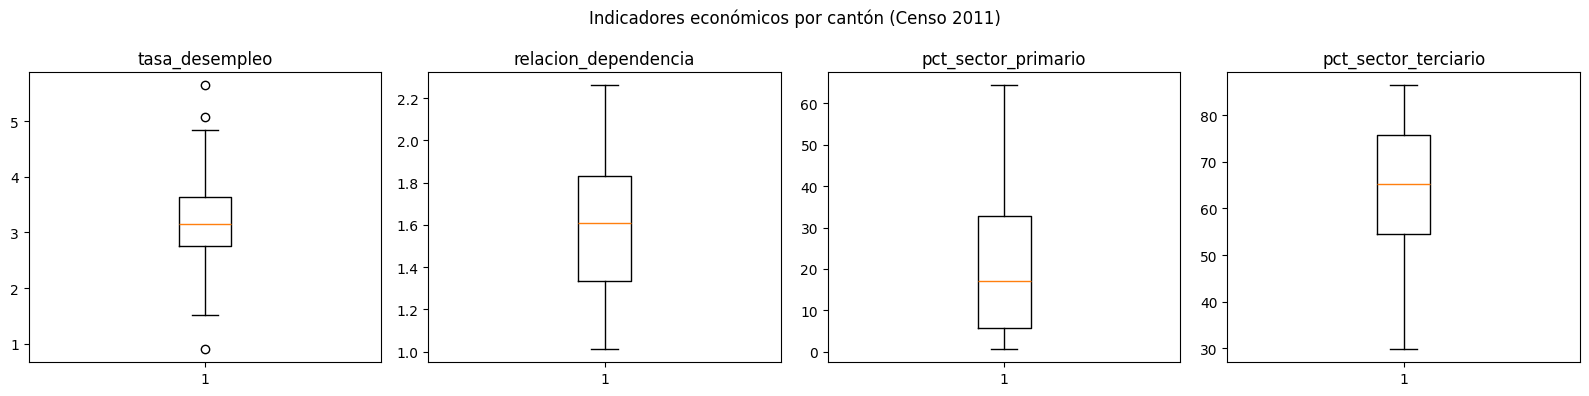

In [28]:
# Diagramas de caja (boxplot): muestran la mediana, los cuartiles y los valores alejados de cada indicador.
censo_pandas = censo_cantones.select(
    "tasa_desempleo", "relacion_dependencia", "pct_sector_primario", "pct_sector_terciario"
).toPandas()

figura, ejes = plt.subplots(1, 4, figsize=(16, 4))
columnas_grafico = ["tasa_desempleo", "relacion_dependencia", "pct_sector_primario", "pct_sector_terciario"]

for posicion in range(len(columnas_grafico)):
    ejes[posicion].boxplot(censo_pandas[columnas_grafico[posicion]])
    ejes[posicion].set_title(columnas_grafico[posicion])

plt.suptitle("Indicadores económicos por cantón (Censo 2011)")
plt.tight_layout()
plt.show()

In [29]:
# Extremos del indicador principal del análisis.
print("Cantones con mayor desempleo:")
censo_cantones.orderBy(F.desc("tasa_desempleo")).select("provincia", "canton", "tasa_desempleo").show(5)

print("Cantones con menor desempleo:")
censo_cantones.orderBy("tasa_desempleo").select("provincia", "canton", "tasa_desempleo").show(5)

Cantones con mayor desempleo:
+----------+---------+------------------+
| provincia|   canton|    tasa_desempleo|
+----------+---------+------------------+
|Guanacaste| Carrillo| 5.646054088249248|
|     Limón|    Limón| 5.063844400736786|
|Guanacaste|  Liberia|4.8423803101820635|
|Guanacaste|Abangares| 4.809683070552636|
|     Limón|   Pococí| 4.482976452392881|
+----------+---------+------------------+
only showing top 5 rows
Cantones con menor desempleo:
+---------+--------+------------------+
|provincia|  canton|    tasa_desempleo|
+---------+--------+------------------+
| Alajuela| Zarcero|0.9072978303747534|
|  Cartago|Alvarado|1.5159527586814736|
| San José|    Dota|1.8147448015122871|
| San José|  Acosta| 2.061310782241015|
| Alajuela|  Atenas|2.1278691754506944|
+---------+--------+------------------+
only showing top 5 rows


### 5.3 Correspondencia de cantones entre las fuentes

El join se hará por nombre de cantón, así que antes hay que revisar si los nombres coinciden entre
las tres fuentes. Se normalizan con `normalizar_texto` y se buscan con un `left_anti` join los
cantones del OIJ que no aparecen en las otras fuentes.

In [30]:
# Se normalizan los nombres de las tres fuentes con la misma función y se comparan.
# left_anti join: devuelve las filas de la izquierda que NO encuentran pareja en la derecha,
# es decir, los cantones del OIJ que no existen en la otra fuente.
cantones_oij = (
    oij_crudo
    .groupBy("canton")
    .count()
    .withColumn("canton_normalizado", normalizar_texto(F.col("canton")))
)

nombres_censo = censo_cantones.select(normalizar_texto(F.col("canton")).alias("canton_normalizado"))
nombres_geo = cantones_geo.select(normalizar_texto(F.col("canton")).alias("canton_normalizado"))

print("Cantones del OIJ que no aparecen en el censo:")
cantones_oij.join(nombres_censo, "canton_normalizado", "left_anti").orderBy(F.desc("count")).show(truncate=False)

print("Cantones del OIJ que no aparecen en el GeoJSON:")
cantones_oij.join(nombres_geo, "canton_normalizado", "left_anti").orderBy(F.desc("count")).show(truncate=False)

Cantones del OIJ que no aparecen en el censo:
+-------------------+-------------------+-----+
|canton_normalizado |canton             |count|
+-------------------+-------------------+-----+
|QUEPOS             |QUEPOS             |3384 |
|VASQUEZ DE CORONADO|VASQUEZ DE CORONADO|1686 |
|DESCONOCIDO        |DESCONOCIDO        |815  |
|PUERTO JIMENEZ     |PUERTO JIM&#201;NEZ|507  |
|MONTEVERDE         |MONTEVERDE         |430  |
|SARCHI             |SARCH&#205;        |292  |
|RIO CUARTO         |RIO CUARTO         |292  |
|LEON CORTES        |LEON CORTES        |176  |
+-------------------+-------------------+-----+

Cantones del OIJ que no aparecen en el GeoJSON:
+-------------------+-------------------+-----+
|canton_normalizado |canton             |count|
+-------------------+-------------------+-----+
|VASQUEZ DE CORONADO|VASQUEZ DE CORONADO|1686 |
|DESCONOCIDO        |DESCONOCIDO        |815  |
|PALMARES           |PALMARES           |631  |
|MONTEVERDE         |MONTEVERDE         |

Las diferencias tienen tres causas:

| Cantón en el OIJ | Censo 2011 | GeoJSON | Causa |
|---|---|---|---|
| QUEPOS | AGUIRRE | Quepos | El cantón cambió de nombre en 2015 |
| SARCHI | VALVERDE VEGA | Sarchi | El cantón cambió de nombre |
| LEON CORTES | LEON CORTES CASTRO | Leon Cortes Castro | Nombre corto frente a nombre oficial |
| VASQUEZ DE CORONADO | VAZQUEZ DE CORONADO | Vazquez de Coronado | Diferencia de ortografía |
| PALMARES | PALMARES | Palmeras | Error de escritura en el GeoJSON |
| RIO CUARTO | no existe | Rio Cuarto | Cantón creado en 2017, a partir de Grecia |
| PUERTO JIMENEZ | no existe | Puerto Jimenez | Cantón creado en 2022, a partir de Golfito |
| MONTEVERDE | no existe | no existe | Cantón creado en 2021, a partir de Puntarenas |
| DESCONOCIDO | no aplica | no aplica | El OIJ no registró la ubicación |

En la etapa de integración se construye una tabla de equivalencias para resolver estos casos.

### 5.4 Resumen del estado inicial de los datos

**OIJ**

| # | Problema de calidad | Tratamiento previsto |
|---|---|---|
| 1 | Encabezado incorrecto: falta la columna de la hora y sobra `Distrito` | Lectura con esquema manual (ya aplicado) |
| 2 | Líneas con una coma sin comillas dentro de la nacionalidad | Reconstruir la nacionalidad y reacomodar las columnas |
| 3 | Entidades HTML en los nombres (`&#201;`, `&#205;`) | Decodificarlas al normalizar el texto |
| 4 | Faltantes registrados como `Desconocido` en edad, sexo, nacionalidad y cantón | Convertir a nulos; imputar o eliminar según la columna |
| 5 | Etiquetas distintas para el mismo subdelito (`POR DESCUIDO` y `DESCUIDO`) | Unificar etiquetas |
| 6 | Registros idénticos sin identificador de caso | Analizar y justificar la decisión |
| 7 | Fecha y hora como texto; la hora es un rango | Convertir la fecha a `date` y derivar la hora de inicio y el periodo del día |
| 8 | Año 2026 incompleto | Tenerlo en cuenta en las comparaciones entre años |

**Censo 2011**

| # | Problema de calidad | Tratamiento previsto |
|---|---|---|
| 1 | Formato de reporte con niveles mezclados | Identificación del nivel por posición (ya aplicado) |
| 2 | Números guardados como texto | Conversión a numérico (ya aplicado) |
| 3 | Nombres de cantón distintos a los del OIJ y cantones creados después de 2011 | Tabla de equivalencias en la integración |

**GeoJSON**

| # | Problema de calidad | Tratamiento previsto |
|---|---|---|
| 1 | Falta el cantón de Monteverde (83 de 84 cantones) | Usar el polígono de Puntarenas, del cual se separó |
| 2 | Error de escritura (`Palmeras`) | Tabla de equivalencias |

## 6. Limpieza y transformación de los datos

Cada paso de esta sección indica el **problema** encontrado en la exploración, la
**transformación** aplicada y su **efecto** sobre los datos. Todas las operaciones se hacen con
Spark. Se parte de `oij_crudo` y se van creando versiones nuevas del DataFrame, sin modificar el
original, para poder comparar el antes y el después.

### 6.1 Reparación de las líneas desplazadas

**Problema:** 9 líneas tienen una nacionalidad con una coma sin comillas (por ejemplo,
`VIRGENES BRITANICAS, ISLAS`). La coma parte el valor en dos columnas y desplaza todo lo que sigue:
la segunda parte de la nacionalidad queda en `provincia`, la provincia queda en `canton` y el
cantón queda en `columna_sobrante`.

**Transformación:** en esas líneas, se une la nacionalidad con su segunda parte y se mueven la
provincia y el cantón a su columna correcta. Luego se elimina `columna_sobrante`.

In [31]:
# Condición reutilizable: una línea está desplazada si columna_sobrante tiene valor.
desplazada = F.col("columna_sobrante").isNotNull()

# En las líneas desplazadas cada valor quedó una columna a la derecha de donde debería:
# - nacionalidad = primera parte + "," + segunda parte (que quedó en provincia)
# - provincia = el valor que quedó en canton
# - canton = el valor que quedó en columna_sobrante
# F.when(condición, nuevo).otherwise(original) solo cambia las filas que cumplen la condición.
oij_reparado = (
    oij_crudo
    .withColumn(
        "nacionalidad",
        F.when(desplazada, F.concat(F.col("nacionalidad"), F.lit(","), F.col("provincia")))
        .otherwise(F.col("nacionalidad")),
    )
    .withColumn("provincia", F.when(desplazada, F.col("canton")).otherwise(F.col("provincia")))
    .withColumn("canton", F.when(desplazada, F.col("columna_sobrante")).otherwise(F.col("canton")))
)

print("Líneas reparadas:")
oij_reparado.filter(desplazada).select("fecha", "nacionalidad", "provincia", "canton").show(truncate=False)

# La columna auxiliar ya cumplió su función y se elimina.
oij_reparado = oij_reparado.drop("columna_sobrante")

Líneas reparadas:
+----------+-------------------------------------+----------+----------+
|fecha     |nacionalidad                         |provincia |canton    |
+----------+-------------------------------------+----------+----------+
|2023-02-09|VIRGENES BRITANICAS, ISLAS           |PUNTARENAS|OSA       |
|2022-02-22|VIRGENES BRITANICAS, ISLAS           |PUNTARENAS|QUEPOS    |
|2021-04-22|VIRGENES DE LOS ESTADOS UNIDOS, ISLAS|PUNTARENAS|MONTEVERDE|
|2021-08-21|VIRGENES BRITANICAS, ISLAS           |PUNTARENAS|OSA       |
|2022-03-16|VIRGENES BRITANICAS, ISLAS           |PUNTARENAS|OSA       |
|2025-09-14|MALVINAS, ISLAS                      |SAN JOSE  |SAN JOSE  |
|2025-10-01|VATICANO, CIUDAD DEL                 |PUNTARENAS|OSA       |
|2025-10-12|VATICANO, CIUDAD DEL                 |HEREDIA   |HEREDIA   |
|2024-03-02|VIRGENES BRITANICAS, ISLAS           |PUNTARENAS|OSA       |
+----------+-------------------------------------+----------+----------+



**Efecto:** las 9 líneas quedan con la nacionalidad completa y con la provincia y el cantón en su
lugar. Los valores `ISLAS` y `CIUDAD DEL` desaparecen de la columna `provincia`.

### 6.2 Estandarización del texto

**Problema:** los textos mezclan mayúsculas y minúsculas (`Mayor de edad` frente a `HOMBRE`),
algunos traen entidades HTML (`SARCH&#205;`, `DISCUSION/RI&#209;A`) y pueden traer espacios de más.

**Transformación:** a todas las columnas de texto se les aplica la función `limpiar_texto`:
quita espacios sobrantes, pasa a mayúsculas, decodifica las entidades HTML y quita las tildes. A
diferencia de `normalizar_texto`, conserva la Ñ, porque este es el texto que se va a mostrar al
usuario (`RIÑA` y no `RINA`).

In [32]:
# Igual que normalizar_texto, pero conserva la Ñ: este es el texto que se muestra al usuario
# ("RIÑA" y no "RINA"). normalizar_texto se reserva para las llaves de comparación.
def limpiar_texto(columna):
    resultado = F.upper(F.trim(columna))
    # Reemplaza cada entidad HTML por su carácter (&#205; → Í).
    for entidad in entidades_html:
        resultado = F.regexp_replace(resultado, entidad, entidades_html[entidad])
    resultado = F.translate(resultado, "ÁÉÍÓÚÜ", "AEIOUU")
    resultado = F.regexp_replace(resultado, "\\s+", " ")
    return resultado


# Columnas de texto que se limpian. La fecha no se incluye porque se convierte a tipo date.
columnas_texto = [
    "delito", "subdelito", "hora", "victima", "subvictima",
    "edad", "sexo", "nacionalidad", "provincia", "canton",
]

# Se aplica limpiar_texto a cada columna y se reemplaza por su versión limpia.
oij_texto = oij_reparado

for columna in columnas_texto:
    oij_texto = oij_texto.withColumn(columna, limpiar_texto(F.col(columna)))

print("Cantones que tenían entidades HTML:")
oij_texto.filter(F.col("canton").isin("SARCHI", "PUERTO JIMENEZ")).groupBy("canton").count().show()

print("Valores de edad estandarizados:")
oij_texto.groupBy("edad").count().show()

Cantones que tenían entidades HTML:
+--------------+-----+
|        canton|count|
+--------------+-----+
|PUERTO JIMENEZ|  507|
|        SARCHI|  292|
+--------------+-----+

Valores de edad estandarizados:
+-------------+------+
|         edad| count|
+-------------+------+
| ADULTO MAYOR| 11872|
|MENOR DE EDAD|  8721|
|MAYOR DE EDAD|206546|
|  DESCONOCIDO| 14359|
+-------------+------+



**Efecto:** `SARCH&#205;` pasa a `SARCHI`, `PUERTO JIM&#201;NEZ` pasa a `PUERTO JIMENEZ` y
`Mayor de edad` pasa a `MAYOR DE EDAD`. Ahora un mismo valor se escribe siempre igual.

### 6.3 Unificación de etiquetas

**Problema 1:** la misma modalidad aparece con dos etiquetas: `POR DESCUIDO` (en hurtos) y
`DESCUIDO` (en robos de vehículo). Ambas describen que el delito se aprovechó de un descuido de la
víctima.

**Problema 2:** `subvictima` repite al final, entre corchetes, el valor de `victima`
(`PEATON [PERSONA]`). Es información redundante que hace los valores más largos.

**Transformación:** se cambia `DESCUIDO` por `POR DESCUIDO` y se elimina el sufijo entre corchetes
de `subvictima`.

In [33]:
# Unificación de etiquetas:
# - "DESCUIDO" (robo de vehículo) pasa a "POR DESCUIDO", la etiqueta que se usa en hurto.
# - En subvictima, una expresión regular quita el texto entre corchetes al final: "PEATON [PERSONA]" → "PEATON".
oij_etiquetas = (
    oij_texto
    .withColumn(
        "subdelito",
        F.when(F.col("subdelito") == "DESCUIDO", F.lit("POR DESCUIDO")).otherwise(F.col("subdelito")),
    )
    .withColumn("subvictima", F.trim(F.regexp_replace(F.col("subvictima"), "\\[[^\\]]*\\]$", "")))
)

print("Subdelito 'POR DESCUIDO' por tipo de delito:")
oij_etiquetas.filter(F.col("subdelito") == "POR DESCUIDO").groupBy("delito").count().show()

print("Subvíctimas después de quitar el sufijo:")
oij_etiquetas.groupBy("victima", "subvictima").count().orderBy(F.desc("count")).show(10, truncate=False)

Subdelito 'POR DESCUIDO' por tipo de delito:
+----------------+-----+
|          delito|count|
+----------------+-----+
|           HURTO|43209|
|ROBO DE VEHICULO|18443|
+----------------+-----+

Subvíctimas después de quitar el sufijo:
+--------+--------------------------------------------+-----+
|victima |subvictima                                  |count|
+--------+--------------------------------------------+-----+
|PERSONA |PEATON                                      |79490|
|VEHICULO|AUTOMOVIL                                   |34711|
|VEHICULO|MOTOCICLETA                                 |18804|
|PERSONA |OTRO O INDETERMINADO                        |18778|
|PERSONA |CLIENTE LOCAL COMERCIAL                     |12262|
|VEHICULO|RURAL 4X4                                   |10174|
|PERSONA |PASAJERO DE TRANSPORTE PUBLICO              |8221 |
|OTROS   |BICICLETA                                   |6990 |
|VEHICULO|CARGA LIVIANA                               |6326 |
|VEHICULO|SERVICIO 

### 6.4 Corrección de tipos de datos

**Problema:** la fecha está guardada como texto y la hora es un rango de texto
(`18:00:00 - 20:59:59`), con el que no se pueden hacer comparaciones ni cálculos.

**Transformación:**
- `fecha` se convierte al tipo `date`.
- Del rango de la hora se extrae la **hora de inicio** como número entero (`18`). Todos los rangos
  duran tres horas, así que la hora de inicio identifica la franja sin perder información.

Antes de convertir, se verifica con una expresión regular que todos los valores tengan el formato
esperado. Si alguno no lo tuviera, la conversión daría nulo y se perdería el dato sin notarlo.

In [34]:
# Expresiones regulares para validar el formato antes de convertir:
# - fecha: cuatro dígitos, guion, dos dígitos, guion, dos dígitos (2019-01-01).
# - hora: "HH:00:00 - HH:59:59".
# rlike devuelve verdadero si el texto calza con la expresión; el símbolo ~ niega la condición.
formato_fecha = "^\\d{4}-\\d{2}-\\d{2}$"
formato_hora = "^\\d{2}:00:00 - \\d{2}:59:59$"

print("Fechas con formato distinto:", oij_etiquetas.filter(~F.col("fecha").rlike(formato_fecha)).count())
print("Horas con formato distinto:", oij_etiquetas.filter(~F.col("hora").rlike(formato_hora)).count())

# - to_date: texto a tipo date.
# - substring("hora", 1, 2): toma los dos primeros caracteres ("18") y cast("int") los vuelve número.
# - La columna original se renombra a franja_horaria porque describe un rango, no una hora.
oij_tipos = (
    oij_etiquetas
    .withColumn("fecha", F.to_date("fecha", "yyyy-MM-dd"))
    .withColumn("hora_inicio", F.substring("hora", 1, 2).cast("int"))
    .withColumnRenamed("hora", "franja_horaria")
)

oij_tipos.select("fecha", "franja_horaria", "hora_inicio").printSchema()

Fechas con formato distinto: 0
Horas con formato distinto: 0
root
 |-- fecha: date (nullable = true)
 |-- franja_horaria: string (nullable = true)
 |-- hora_inicio: integer (nullable = true)



### 6.5 Valores fuera de rango y valores atípicos

Se revisan cuatro columnas: dos del OIJ con **reglas de rango** (valores que no pueden existir) y
dos del censo, más la cantidad de delitos por día, con el **método del rango intercuartílico
(IQR)** (valores posibles, pero muy alejados del resto).

#### Reglas de rango en el OIJ

- `fecha`: debe estar entre el 1 de enero de 2019 (inicio del periodo descargado) y la fecha de
  corte de los datos. Una fecha futura indicaría un error de digitación.
- `hora_inicio`: las franjas son de tres horas, así que solo puede valer 0, 3, 6, ..., 21.

In [35]:
# Reglas de rango: la fecha debe estar entre el inicio del periodo descargado y hoy,
# y la hora de inicio debe ser un múltiplo de 3 (las franjas son de tres horas).
fecha_inicio_periodo = "2019-01-01"
fecha_corte = oij_tipos.agg(F.max("fecha")).first()[0]
horas_validas = [0, 3, 6, 9, 12, 15, 18, 21]

fuera_rango_fecha = oij_tipos.filter(
    (F.col("fecha") < F.lit(fecha_inicio_periodo)) | (F.col("fecha") > F.current_date())
).count()

fuera_rango_hora = oij_tipos.filter(~F.col("hora_inicio").isin(horas_validas)).count()

print("Fecha de corte de los datos:", fecha_corte)
print("Fechas fuera de rango:", fuera_rango_fecha)
print("Horas fuera de rango:", fuera_rango_hora)

Fecha de corte de los datos: 2026-11-22
Fechas fuera de rango: 0
Horas fuera de rango: 0


Ningún registro viola las reglas de rango, así que no hay que eliminar ni corregir nada en estas
columnas. Que la verificación salga limpia también es un resultado: confirma que la fecha y la
hora se pueden usar con confianza en las consultas por rango.

#### Valores atípicos con el rango intercuartílico

El método IQR calcula el primer cuartil $Q_1$ y el tercer cuartil $Q_3$ de una variable, y marca
como atípico todo valor que quede fuera de:

$$
[\,Q_1 - 1.5 \cdot IQR,\; Q_3 + 1.5 \cdot IQR\,] \qquad \text{donde} \qquad IQR = Q_3 - Q_1
$$

In [36]:
# approxQuantile calcula percentiles en Spark; con error relativo 0.0 el cálculo es exacto.
# Devuelve los límites inferior y superior del método IQR.
def limites_iqr(df, columna):
    cuartiles = df.approxQuantile(columna, [0.25, 0.75], 0.0)
    q1 = cuartiles[0]
    q3 = cuartiles[1]
    rango = q3 - q1
    return q1 - 1.5 * rango, q3 + 1.5 * rango


# Aplica los límites IQR a una columna y muestra cuántos valores quedan fuera y cuáles son.
def revisar_atipicos(df, columna, columnas_mostrar):
    limite_inferior, limite_superior = limites_iqr(df, columna)
    atipicos = df.filter((F.col(columna) < limite_inferior) | (F.col(columna) > limite_superior))
    print("Columna:", columna)
    print("Límites:", round(limite_inferior, 3), "a", round(limite_superior, 3))
    print("Valores atípicos:", atipicos.count(), "de", df.count())
    atipicos.select(columnas_mostrar).orderBy(F.desc(columna)).show(10, truncate=False)

In [37]:
# Se revisan tres variables: delitos por día (OIJ) y dos indicadores del censo.
delitos_diarios = oij_tipos.groupBy("fecha").count().withColumnRenamed("count", "delitos_dia")

revisar_atipicos(delitos_diarios, "delitos_dia", ["fecha", "delitos_dia"])
revisar_atipicos(censo_cantones, "tasa_desempleo", ["provincia", "canton", "tasa_desempleo"])
revisar_atipicos(censo_cantones, "pct_sector_primario", ["provincia", "canton", "pct_sector_primario"])

Columna: delitos_dia
Límites: 31.0 a 135.0
Valores atípicos: 40 de 2883
+----------+-----------+
|fecha     |delitos_dia|
+----------+-----------+
|2023-10-28|188        |
|2024-02-10|169        |
|2020-02-29|160        |
|2022-10-29|155        |
|2019-06-15|153        |
|2025-11-01|153        |
|2024-06-30|153        |
|2019-06-23|151        |
|2019-10-27|150        |
|2024-11-01|148        |
+----------+-----------+
only showing top 10 rows
Columna: tasa_desempleo
Límites: 1.445 a 4.947
Valores atípicos: 3 de 81
+----------+--------+------------------+
|provincia |canton  |tasa_desempleo    |
+----------+--------+------------------+
|Guanacaste|Carrillo|5.646054088249248 |
|Limón     |Limón   |5.063844400736786 |
|Alajuela  |Zarcero |0.9072978303747534|
+----------+--------+------------------+

Columna: pct_sector_primario
Límites: -34.413 a 72.948
Valores atípicos: 0 de 81
+---------+------+-------------------+
|provincia|canton|pct_sector_primario|
+---------+------+---------------

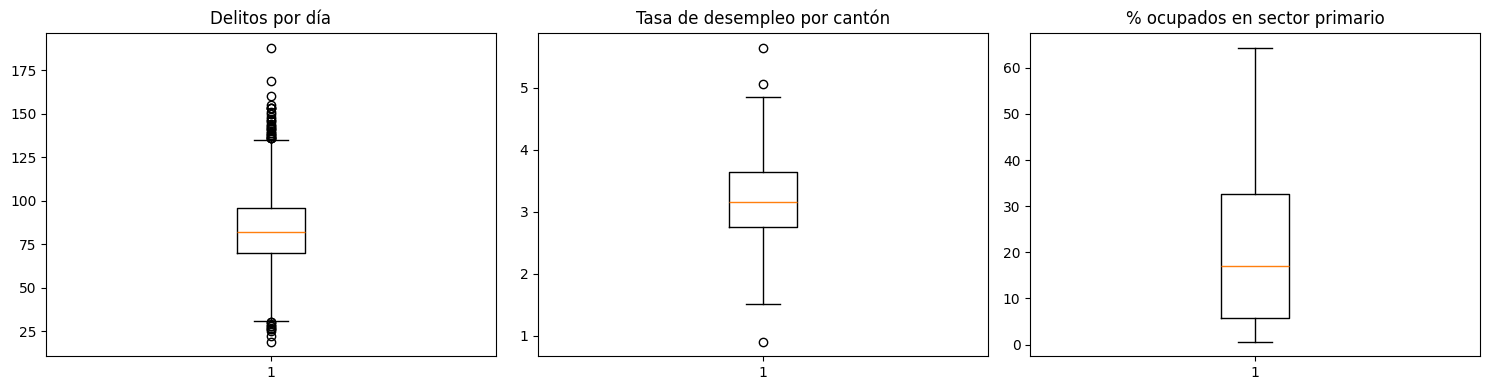

In [38]:
# Tres diagramas de caja lado a lado: los puntos fuera de los bigotes son los valores atípicos.
figura, ejes = plt.subplots(1, 3, figsize=(15, 4))

ejes[0].boxplot(delitos_diarios.select("delitos_dia").toPandas()["delitos_dia"])
ejes[0].set_title("Delitos por día")
ejes[1].boxplot(censo_cantones.select("tasa_desempleo").toPandas()["tasa_desempleo"])
ejes[1].set_title("Tasa de desempleo por cantón")
ejes[2].boxplot(censo_cantones.select("pct_sector_primario").toPandas()["pct_sector_primario"])
ejes[2].set_title("% ocupados en sector primario")

plt.tight_layout()
plt.show()

**Decisión:** los valores atípicos encontrados **se conservan**. No son errores: son días con
mucha más actividad delictiva que lo normal, o cantones con condiciones económicas extremas, y
justamente esos casos son los que interesa analizar. Eliminarlos haría desaparecer la información
más relevante del estudio. Un análisis más profundo de estos casos se hace en la sección de
detección de anomalías.

### 6.6 Registros duplicados

**Problema:** 12 517 registros son idénticos a otro en todas sus columnas.

**Análisis:** el archivo no trae un número de caso, y sus columnas son muy generales: fecha, franja
de tres horas, cantón, rango de edad, sexo y nacionalidad. Dos delitos distintos pueden coincidir en
todo eso. Si los duplicados fueran errores de captura, deberían repartirse al azar. Si son
coincidencias reales, deberían concentrarse donde hay más delitos, porque ahí es más probable que
dos casos coincidan. Se compara cuánto pesa cada cantón entre los duplicados y entre todos los
registros.

In [39]:
# Columnas que describen un delito. Dos registros son "idénticos" si coinciden en todas.
columnas_registro = [
    "delito", "subdelito", "fecha", "franja_horaria", "victima", "subvictima",
    "edad", "sexo", "nacionalidad", "provincia", "canton",
]

# partitionBy junta las filas idénticas en la misma ventana. count("*") sobre esa ventana dice
# cuántas veces aparece cada registro, sin colapsar las filas (a diferencia de groupBy).
ventana_repetidos = Window.partitionBy(*columnas_registro)

oij_con_repeticiones = oij_tipos.withColumn("veces_repetido", F.count("*").over(ventana_repetidos))

total_registros = oij_tipos.count()
registros_repetidos = oij_con_repeticiones.filter(F.col("veces_repetido") > 1)
total_repetidos = registros_repetidos.count()

# Porcentaje de cada cantón entre todos los registros y entre los repetidos.
# Si los repetidos fueran errores al azar, ambos porcentajes serían parecidos.
participacion_total = (
    oij_tipos.groupBy("canton").count()
    .withColumn("pct_de_todos", F.round(F.col("count") / total_registros * 100, 2))
    .drop("count")
)

participacion_repetidos = (
    registros_repetidos.groupBy("canton").count()
    .withColumn("pct_de_repetidos", F.round(F.col("count") / total_repetidos * 100, 2))
    .drop("count")
)

participacion_total.join(participacion_repetidos, "canton").orderBy(F.desc("pct_de_todos")).show(8)

+------------+------------+----------------+
|      canton|pct_de_todos|pct_de_repetidos|
+------------+------------+----------------+
|    SAN JOSE|       23.85|           31.87|
|    ALAJUELA|        6.39|            5.05|
|     HEREDIA|        4.06|            4.41|
|  PUNTARENAS|        3.22|            3.66|
|     CARTAGO|        3.07|            1.96|
|DESAMPARADOS|        2.96|            2.91|
|  SAN CARLOS|        2.34|            1.64|
|       LIMON|        2.32|            2.37|
+------------+------------+----------------+
only showing top 8 rows


San José, que es por mucho el cantón con más delitos, representa el 23,9 % de todos los registros
pero el 31,9 % de los repetidos. Es decir, los registros repetidos se concentran donde hay más
volumen, que es lo que se espera de coincidencias reales y no de errores de captura (en los demás
cantones las diferencias son pequeñas en ambos sentidos).

**Decisión:** los registros repetidos **se conservan**, porque eliminarlos borraría delitos reales y
subestimaría la criminalidad justo en los cantones con más casos. Para cumplir con que no existan
registros duplicados, a cada registro se le agrega un **número de ocurrencia** dentro de su grupo
de registros idénticos (1, 2, 3...). Con ese número, cada fila queda distinta. A partir de todas
las columnas y el número de ocurrencia se genera un **identificador único** con la función hash
SHA-256. A diferencia de un consecutivo, ese identificador es reproducible: si se vuelve a ejecutar
el pipeline, cada registro recibe el mismo identificador.

In [40]:
# row_number numera las filas dentro de cada grupo de registros idénticos (1, 2, 3...).
# orderBy(F.lit(1)): el orden dentro del grupo no importa porque las filas son iguales.
ventana_ocurrencia = Window.partitionBy(*columnas_registro).orderBy(F.lit(1))

# Lista de columnas que forman el identificador: todas las del registro más el número de ocurrencia.
# coalesce(..., "") evita que un valor nulo anule toda la concatenación.
columnas_para_id = []
for columna in columnas_registro:
    columnas_para_id.append(F.coalesce(F.col(columna).cast("string"), F.lit("")))
columnas_para_id.append(F.col("numero_ocurrencia").cast("string"))

# concat_ws une las columnas separadas por "|"; sha2(..., 256) calcula el hash SHA-256 de ese texto,
# y substring toma los primeros 16 caracteres. El mismo registro produce siempre el mismo id.
oij_sin_duplicados = (
    oij_tipos
    .withColumn("numero_ocurrencia", F.row_number().over(ventana_ocurrencia))
    .withColumn("id", F.substring(F.sha2(F.concat_ws("|", *columnas_para_id), 256), 1, 16))
)

print("Registros:", oij_sin_duplicados.count())
print("Registros distintos (con número de ocurrencia):", oij_sin_duplicados.distinct().count())
print("Identificadores distintos:", oij_sin_duplicados.select("id").distinct().count())

Registros: 241498
Registros distintos (con número de ocurrencia): 241498
Identificadores distintos: 241498


**Efecto:** se conservan los 241 498 registros, ninguno es idéntico a otro y cada uno tiene un
identificador único que después se usa como llave de los documentos en Solr.

### 6.7 Variables derivadas

Se crean variables nuevas a partir de las existentes, pensadas para el análisis y para las
consultas de la aplicación:

| Variable | Cálculo | Utilidad |
|---|---|---|
| `anio`, `mes` | Extraídos de `fecha` | Comparar periodos y hacer facets por año |
| `dia_semana` | Nombre del día de la semana de `fecha` | Ver qué días ocurren más delitos |
| `es_fin_de_semana` | Sábado o domingo | Filtro booleano |
| `periodo_dia` | `hora_inicio` agrupada en madrugada (0-5), mañana (6-11), tarde (12-17) y noche (18-23) | Una categoría más fácil de interpretar que 8 franjas |

La tasa de delitos por cada 1000 habitantes se calcula en la integración, porque necesita la
población que viene del censo.

In [41]:
# dayofweek devuelve 1 = domingo, 2 = lunes, ..., 7 = sábado.
numero_dia = F.dayofweek("fecha")

oij_derivado = (
    oij_sin_duplicados
    .withColumn("anio", F.year("fecha"))
    .withColumn("mes", F.month("fecha"))
    .withColumn(
        "dia_semana",
        F.when(numero_dia == 1, "DOMINGO")
        .when(numero_dia == 2, "LUNES")
        .when(numero_dia == 3, "MARTES")
        .when(numero_dia == 4, "MIERCOLES")
        .when(numero_dia == 5, "JUEVES")
        .when(numero_dia == 6, "VIERNES")
        .otherwise("SABADO"),
    )
    # Fin de semana: domingo (1) o sábado (7).
    .withColumn("es_fin_de_semana", numero_dia.isin(1, 7))
    .withColumn(
        "periodo_dia",
        F.when(F.col("hora_inicio") < 6, "MADRUGADA")
        .when(F.col("hora_inicio") < 12, "MAÑANA")
        .when(F.col("hora_inicio") < 18, "TARDE")
        .otherwise("NOCHE"),
    )
)

oij_derivado.select("fecha", "anio", "mes", "dia_semana", "es_fin_de_semana", "hora_inicio", "periodo_dia").show(5)

+----------+----+---+----------+----------------+-----------+-----------+
|     fecha|anio|mes|dia_semana|es_fin_de_semana|hora_inicio|periodo_dia|
+----------+----+---+----------+----------------+-----------+-----------+
|2019-01-01|2019|  1|    MARTES|           false|          6|     MAÑANA|
|2019-01-06|2019|  1|   DOMINGO|            true|         18|      NOCHE|
|2019-01-07|2019|  1|     LUNES|           false|          9|     MAÑANA|
|2019-01-11|2019|  1|   VIERNES|           false|          9|     MAÑANA|
|2019-01-14|2019|  1|     LUNES|           false|         18|      NOCHE|
+----------+----+---+----------+----------------+-----------+-----------+
only showing top 5 rows


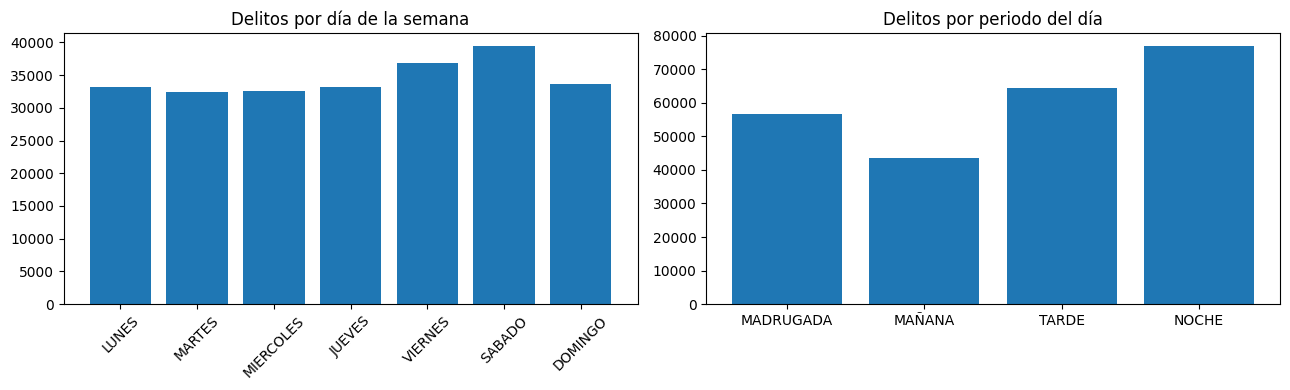

In [42]:
# Orden lógico de días y periodos, para que los gráficos no salgan en orden alfabético.
orden_dias = ["LUNES", "MARTES", "MIERCOLES", "JUEVES", "VIERNES", "SABADO", "DOMINGO"]
orden_periodos = ["MADRUGADA", "MAÑANA", "TARDE", "NOCHE"]

delitos_dia_semana = oij_derivado.groupBy("dia_semana").count().toPandas().set_index("dia_semana").loc[orden_dias]
delitos_periodo = oij_derivado.groupBy("periodo_dia").count().toPandas().set_index("periodo_dia").loc[orden_periodos]

figura, ejes = plt.subplots(1, 2, figsize=(13, 4))
ejes[0].bar(delitos_dia_semana.index, delitos_dia_semana["count"])
ejes[0].set_title("Delitos por día de la semana")
ejes[0].tick_params(axis="x", rotation=45)
ejes[1].bar(delitos_periodo.index, delitos_periodo["count"])
ejes[1].set_title("Delitos por periodo del día")
plt.tight_layout()
plt.show()

#### Variables derivadas del censo

En el censo también se crean dos variables categóricas, útiles para los facets de Solr:

- `economia_predominante`: el sector (primario, secundario o terciario) con mayor porcentaje de
  población ocupada en el cantón.
- `nivel_desempleo`: el cantón se clasifica como `BAJO`, `MEDIO` o `ALTO` según el tercil de su tasa
  de desempleo. Usar terciles garantiza que cada nivel tenga aproximadamente la misma cantidad de
  cantones.

In [43]:
# Terciles: los valores que dividen los cantones en tres grupos del mismo tamaño (33 % y 66 %).
terciles_desempleo = censo_cantones.approxQuantile("tasa_desempleo", [1 / 3, 2 / 3], 0.0)
print("Límites de los terciles de desempleo:", terciles_desempleo)

# - economia_predominante: el sector con mayor porcentaje de ocupados.
# - nivel_desempleo: BAJO, MEDIO o ALTO según el tercil en que cae la tasa de desempleo del cantón.
censo_derivado = (
    censo_cantones
    .withColumn(
        "economia_predominante",
        F.when(
            (F.col("pct_sector_primario") >= F.col("pct_sector_secundario"))
            & (F.col("pct_sector_primario") >= F.col("pct_sector_terciario")),
            "PRIMARIO",
        )
        .when(F.col("pct_sector_secundario") >= F.col("pct_sector_terciario"), "SECUNDARIO")
        .otherwise("TERCIARIO"),
    )
    .withColumn(
        "nivel_desempleo",
        F.when(F.col("tasa_desempleo") <= terciles_desempleo[0], "BAJO")
        .when(F.col("tasa_desempleo") <= terciles_desempleo[1], "MEDIO")
        .otherwise("ALTO"),
    )
)

censo_derivado.groupBy("economia_predominante").count().show()
censo_derivado.groupBy("nivel_desempleo").count().show()

Límites de los terciles de desempleo: [2.860978806380462, 3.5159767010271388]
+---------------------+-----+
|economia_predominante|count|
+---------------------+-----+
|            TERCIARIO|   70|
|             PRIMARIO|   11|
+---------------------+-----+

+---------------+-----+
|nivel_desempleo|count|
+---------------+-----+
|           ALTO|   27|
|          MEDIO|   27|
|           BAJO|   27|
+---------------+-----+



Ningún cantón tiene como sector predominante el secundario (industria): en todos, el terciario o el
primario emplea a más personas. La variable queda con dos categorías: 70 cantones de economía de
servicios y 11 de economía agrícola. Esa diferencia es una de las comparaciones centrales del
análisis.

## 7. Tratamiento e imputación de datos faltantes

### 7.1 Inventario de valores faltantes

Primero, el texto `DESCONOCIDO` se convierte en un nulo real, para que Spark lo trate como un valor
faltante. Luego se calcula la cantidad y el porcentaje de faltantes por columna.

In [44]:
# Columnas donde el OIJ usa el texto "DESCONOCIDO" para indicar que no tiene el dato.
columnas_con_desconocido = ["subdelito", "edad", "sexo", "nacionalidad", "provincia", "canton"]

# Se reemplaza "DESCONOCIDO" por un nulo real (None), que es como Spark representa un faltante.
oij_nulos = oij_derivado
for columna in columnas_con_desconocido:
    oij_nulos = oij_nulos.withColumn(
        columna, F.when(F.col(columna) == "DESCONOCIDO", F.lit(None)).otherwise(F.col(columna))
    )

oij_nulos.cache()
total_nulos = oij_nulos.count()


# Función de apoyo: cantidad y porcentaje de nulos por columna.
def mostrar_faltantes(df, columnas):
    filas = []
    total = df.count()
    for columna in columnas:
        faltantes = df.filter(F.col(columna).isNull()).count()
        filas.append((columna, faltantes, round(faltantes / total * 100, 2)))
    spark.createDataFrame(filas, ["columna", "faltantes", "porcentaje"]).show(truncate=False)


mostrar_faltantes(oij_nulos, columnas_con_desconocido)

+------------+---------+----------+
|columna     |faltantes|porcentaje|
+------------+---------+----------+
|subdelito   |190      |0.08      |
|edad        |14359    |5.95      |
|sexo        |15213    |6.3       |
|nacionalidad|10359    |4.29      |
|provincia   |24       |0.01      |
|canton      |815      |0.34      |
+------------+---------+----------+



### 7.2 Faltantes que no son faltantes: víctimas institucionales

Antes de decidir cómo imputar, se revisa **dónde** faltan los datos. Si los faltantes se repartieran
al azar, se podrían imputar con cualquier método razonable. Pero el porcentaje de sexo faltante
cambia mucho según el tipo de víctima:

In [45]:
(
    oij_nulos
    # Porcentaje de faltantes de sexo y edad según el tipo de víctima.
    # isNull().cast("int") vale 1 si falta y 0 si no; su promedio es la proporción de faltantes.
    .groupBy("victima", "subvictima")
    .agg(
        F.count("*").alias("registros"),
        F.round(F.avg(F.col("sexo").isNull().cast("int")) * 100, 1).alias("pct_sexo_faltante"),
        F.round(F.avg(F.col("edad").isNull().cast("int")) * 100, 1).alias("pct_edad_faltante"),
    )
    .filter(F.col("registros") >= 30)
    .orderBy(F.desc("pct_sexo_faltante"))
    .show(12, truncate=False)
)

+--------+-----------------------------------+---------+-----------------+-----------------+
|victima |subvictima                         |registros|pct_sexo_faltante|pct_edad_faltante|
+--------+-----------------------------------+---------+-----------------+-----------------+
|OTROS   |ENTIDADES PUBLICAS NO FINANCIERAS  |4129     |63.0             |63.5             |
|OTROS   |EL ESTADO                          |829      |57.7             |57.4             |
|OTROS   |SERVICIO PUBLICO                   |182      |50.0             |47.8             |
|OTROS   |ENTIDADES COMERCIALES Y FINANCIERAS|743      |49.1             |48.5             |
|OTROS   |CAJERO AUTOMATICO                  |32       |34.4             |28.1             |
|OTROS   |NO DEFINIDO                        |2387     |28.4             |26.6             |
|VEHICULO|FURGON O CONTENEDOR                |1170     |16.7             |19.5             |
|VEHICULO|CARGA LIVIANA/REPARTIDOR           |1538     |16.3          

Los porcentajes más altos corresponden a víctimas que **no son personas**: entidades públicas, el
Estado, comercios, servicios públicos o cajeros automáticos. En esos casos el sexo, la edad y la
nacionalidad no se desconocen: **no aplican**. Imputarles un valor (decir que el Estado es
`HOMBRE`) sería inventar información.

**Decisión:** en las víctimas institucionales, los faltantes de sexo, edad y nacionalidad se
reemplazan por la categoría `NO APLICA`. Si el registro sí trae un valor (por ejemplo, la persona
que atendía el comercio), se conserva.

In [46]:
# Víctimas que no son personas: en ellas el sexo, la edad y la nacionalidad no aplican.
subvictimas_institucionales = [
    "ENTIDADES PUBLICAS NO FINANCIERAS",
    "EL ESTADO",
    "ENTIDADES COMERCIALES Y FINANCIERAS",
    "SERVICIO PUBLICO",
    "CAJERO AUTOMATICO",
    "EL AMBIENTE",
]

es_institucional = F.col("subvictima").isin(subvictimas_institucionales)

# Solo se reemplazan los nulos de víctimas institucionales; si el registro trae un valor, se conserva.
oij_no_aplica = oij_nulos
for columna in ["sexo", "edad", "nacionalidad"]:
    oij_no_aplica = oij_no_aplica.withColumn(
        columna,
        F.when(es_institucional & F.col(columna).isNull(), F.lit("NO APLICA")).otherwise(F.col(columna)),
    )

mostrar_faltantes(oij_no_aplica, columnas_con_desconocido)

+------------+---------+----------+
|columna     |faltantes|porcentaje|
+------------+---------+----------+
|subdelito   |190      |0.08      |
|edad        |10804    |4.47      |
|sexo        |11662    |4.83      |
|nacionalidad|7060     |2.92      |
|provincia   |24       |0.01      |
|canton      |815      |0.34      |
+------------+---------+----------+



### 7.3 Eliminación de registros sin ubicación

**Problema:** 815 registros (0,34 %) no tienen cantón. Algunos tampoco tienen provincia.

**Decisión:** se **eliminan**. La ubicación es la base del proyecto: con ella se generan las
coordenadas y se hace el join con el censo. Imputar un cantón (por ejemplo, el más frecuente)
pondría esos delitos en un lugar donde no ocurrieron y alteraría justo las consultas geoespaciales
y la relación con los indicadores económicos. Como son pocos registros, eliminarlos no cambia las
distribuciones del resto de las variables.

In [47]:
# Se eliminan los registros sin cantón: sin ubicación no se pueden generar coordenadas ni unir con el censo.
antes_eliminacion = oij_no_aplica.count()
oij_con_ubicacion = oij_no_aplica.filter(F.col("canton").isNotNull())
despues_eliminacion = oij_con_ubicacion.count()

print("Registros antes:", antes_eliminacion)
print("Registros eliminados:", antes_eliminacion - despues_eliminacion)
print("Registros después:", despues_eliminacion)
print("Registros sin provincia que quedan:", oij_con_ubicacion.filter(F.col("provincia").isNull()).count())

Registros antes: 241498
Registros eliminados: 815
Registros después: 240683
Registros sin provincia que quedan: 0


### 7.4 Imputación del sexo: aleatoria proporcional por grupo

**Problema:** 4,8 % de las víctimas que sí son personas o vehículos no tienen sexo registrado.

**Por qué no usar la moda:** el valor más frecuente es `HOMBRE` (cerca del 68 %). Si todos los
faltantes se llenaran con `HOMBRE`, la proporción de hombres subiría artificialmente.

**Estrategia:** imputación **aleatoria proporcional por grupo**. Para cada combinación de `delito` y
`subvictima` se calcula la proporción de hombres entre los casos conocidos. Luego, a cada faltante
de ese grupo se le asigna `HOMBRE` con esa probabilidad y `MUJER` con la probabilidad restante,
usando un número aleatorio con semilla fija (para que el resultado sea reproducible).

Así se respetan las diferencias entre grupos: entre los taxistas asaltados casi todas las víctimas
son hombres, y entre los hurtos a clientes de comercios la proporción es más pareja.

In [48]:
# Proporción de hombres entre todos los casos con sexo conocido.
# Se usa como respaldo si un grupo no tiene ningún caso conocido.
proporcion_hombres_global = (
    oij_con_ubicacion
    .filter(F.col("sexo").isin("HOMBRE", "MUJER"))
    .agg(F.avg((F.col("sexo") == "HOMBRE").cast("int")))
    .first()[0]
)

# Proporción de hombres en cada combinación de delito y subvíctima.
# (sexo == "HOMBRE").cast("int") vale 1 o 0; su promedio es la proporción.
proporcion_por_grupo = (
    oij_con_ubicacion
    .filter(F.col("sexo").isin("HOMBRE", "MUJER"))
    .groupBy("delito", "subvictima")
    .agg(F.avg((F.col("sexo") == "HOMBRE").cast("int")).alias("proporcion_hombres"))
)

print("Proporción de hombres global:", round(proporcion_hombres_global, 4))
proporcion_por_grupo.orderBy(F.desc("proporcion_hombres")).show(5, truncate=False)

Proporción de hombres global: 0.682
+---------+--------------------------------+------------------+
|delito   |subvictima                      |proporcion_hombres|
+---------+--------------------------------+------------------+
|ASALTO   |CARGA LIVIANA/MENSAJERO/COBRADOR|1.0               |
|HOMICIDIO|DELINCUENTE (RECONOCIDO)        |1.0               |
|HOMICIDIO|PRIVADO DE LIBERTAD             |1.0               |
|ASALTO   |CAJERO AUTOMATICO               |1.0               |
|HOMICIDIO|COBRADOR/MENSAJERO/PAGADOR      |1.0               |
+---------+--------------------------------+------------------+
only showing top 5 rows


In [49]:
# Imputación aleatoria proporcional:
# 1. Se une a cada registro la proporción de hombres de su grupo.
# 2. rand(seed=42) genera un número aleatorio entre 0 y 1; la semilla hace el resultado reproducible.
# 3. Si el número es menor que la proporción → HOMBRE; si no → MUJER.
#    Ejemplo: si el grupo tiene 0,7 de hombres, cerca del 70 % de sus faltantes recibe HOMBRE.
# 4. sexo_imputado se calcula ANTES de reemplazar, para saber cuáles valores fueron imputados.
oij_sexo = (
    oij_con_ubicacion
    .join(proporcion_por_grupo, ["delito", "subvictima"], "left")
    .withColumn("proporcion_hombres", F.coalesce(F.col("proporcion_hombres"), F.lit(proporcion_hombres_global)))
    .withColumn("aleatorio", F.rand(seed=42))
    .withColumn("sexo_imputado", F.col("sexo").isNull())
    .withColumn(
        "sexo",
        F.when(
            F.col("sexo").isNull(),
            F.when(F.col("aleatorio") < F.col("proporcion_hombres"), "HOMBRE").otherwise("MUJER"),
        ).otherwise(F.col("sexo")),
    )
    .drop("proporcion_hombres", "aleatorio")
)

print("Valores imputados:", oij_sexo.filter(F.col("sexo_imputado")).count())

print("Distribución del sexo antes de imputar (sin faltantes):")
contar_por_valor(oij_con_ubicacion.filter(F.col("sexo").isNotNull()), "sexo")
print("Distribución del sexo después de imputar:")
contar_por_valor(oij_sexo, "sexo")

Valores imputados: 11544
Distribución del sexo antes de imputar (sin faltantes):
+---------+------+----------+
|sexo     |count |porcentaje|
+---------+------+----------+
|HOMBRE   |153855|67.14     |
|MUJER    |71750 |31.31     |
|NO APLICA|3534  |1.54      |
+---------+------+----------+

Distribución del sexo después de imputar:
+---------+------+----------+
|sexo     |count |porcentaje|
+---------+------+----------+
|HOMBRE   |162015|67.31     |
|MUJER    |75134 |31.22     |
|NO APLICA|3534  |1.47      |
+---------+------+----------+



**Efecto:** la proporción entre hombres y mujeres se mantiene prácticamente igual antes y después
de imputar, que era el objetivo. La columna `sexo_imputado` deja registro de cuáles valores fueron
imputados, por si un análisis posterior necesita excluirlos.

### 7.5 Imputación de la edad: moda condicional por subvíctima

**Problema:** 4,5 % de los registros no tienen rango de edad, después de marcar las víctimas
institucionales.

**Estrategia:** imputación por **moda condicional**: el faltante se llena con el rango de edad más
frecuente **dentro de su misma subvíctima**. Es distinta a la usada en el sexo, y se justifica
porque la subvíctima casi determina la edad: si la subvíctima es `ESTUDIANTE` o `MENOR DE EDAD`, lo
más probable es un menor; si es `TAXISTA` o `CLIENTE BANCARIO`, un adulto. Una moda global llenaría
todo con `MAYOR DE EDAD`, incluidos los estudiantes.

In [50]:
# Cuántas veces aparece cada rango de edad dentro de cada subvíctima (sin contar NO APLICA).
conteo_edad = (
    oij_sexo
    .filter(F.col("edad").isNotNull() & (F.col("edad") != "NO APLICA"))
    .groupBy("subvictima", "edad")
    .count()
)

# Dentro de cada subvíctima se ordena de mayor a menor frecuencia: la primera fila es la moda.
# F.asc("edad") desempata en orden alfabético, para que el resultado sea siempre el mismo.
ventana_moda = Window.partitionBy("subvictima").orderBy(F.desc("count"), F.asc("edad"))

moda_edad = (
    conteo_edad
    .withColumn("posicion", F.row_number().over(ventana_moda))
    .filter(F.col("posicion") == 1)
    .select("subvictima", F.col("edad").alias("edad_moda"))
)

# Moda global: respaldo para las subvíctimas sin ningún caso con edad conocida.
moda_edad_global = conteo_edad.groupBy("edad").agg(F.sum("count").alias("total")).orderBy(F.desc("total")).first()["edad"]

print("Moda de edad por subvíctima (no todas son MAYOR DE EDAD):")
moda_edad.filter(F.col("edad_moda") != "MAYOR DE EDAD").show(truncate=False)

Moda de edad por subvíctima (no todas son MAYOR DE EDAD):
+-------------+-------------+
|subvictima   |edad_moda    |
+-------------+-------------+
|ESTUDIANTE   |MENOR DE EDAD|
|MENOR DE EDAD|MENOR DE EDAD|
+-------------+-------------+



In [51]:
# coalesce devuelve el primer valor no nulo: la edad original; si no hay, la moda de su subvíctima;
# y si tampoco existe, la moda global.
oij_edad = (
    oij_sexo
    .join(moda_edad, "subvictima", "left")
    .withColumn("edad_imputada", F.col("edad").isNull())
    .withColumn("edad", F.coalesce(F.col("edad"), F.col("edad_moda"), F.lit(moda_edad_global)))
    .drop("edad_moda")
)

print("Valores imputados:", oij_edad.filter(F.col("edad_imputada")).count())
print("Rango de edad imputado según la subvíctima:")
oij_edad.filter(F.col("edad_imputada")).groupBy("edad").count().show()

Valores imputados: 10687
Rango de edad imputado según la subvíctima:
+-------------+-----+
|         edad|count|
+-------------+-----+
|MAYOR DE EDAD|10460|
|MENOR DE EDAD|  227|
+-------------+-----+



### 7.6 Nacionalidad y subdelito: categoría explícita

**Nacionalidad:** tiene 133 valores distintos, y en casi todos los cantones el más frecuente es
`COSTA RICA`. Imputar con la moda convertiría todos los faltantes en costarricenses, y una
imputación aleatoria entre 133 países produciría nacionalidades poco creíbles en cantones con pocos
casos. Como la nacionalidad no es una variable central del análisis, los faltantes se reemplazan por
la categoría `NO REGISTRADA`. Así se conservan los registros sin inventar información, y en la
aplicación se puede filtrar esa categoría.

**Subdelito:** los 190 faltantes (0,08 %) se asignan a la categoría que ya existe en los datos
para estos casos: `OTRO O INDETERMINADO`.

In [52]:
# Imputación por categoría explícita: el faltante se reemplaza por un valor que indica que no se registró.
oij_imputado = (
    oij_edad
    .withColumn("nacionalidad", F.coalesce(F.col("nacionalidad"), F.lit("NO REGISTRADA")))
    .withColumn("subdelito", F.coalesce(F.col("subdelito"), F.lit("OTRO O INDETERMINADO")))
)

### 7.7 Verificación final

Después de la limpieza y la imputación no debe quedar ningún nulo. Los 24 registros sin provincia
eran también registros sin cantón, así que se eliminaron en el paso 7.3.

In [53]:
oij_imputado.cache()

# Columnas que pasan a la siguiente etapa.
columnas_finales = [
    "id", "delito", "subdelito", "fecha", "franja_horaria", "hora_inicio", "victima", "subvictima",
    "edad", "sexo", "nacionalidad", "provincia", "canton", "anio", "mes", "dia_semana",
    "es_fin_de_semana", "periodo_dia", "sexo_imputado", "edad_imputada",
]

mostrar_faltantes(oij_imputado, columnas_finales)

print("Resumen de imputación:")
print("Sexo imputado:", oij_imputado.filter(F.col("sexo_imputado")).count())
print("Edad imputada:", oij_imputado.filter(F.col("edad_imputada")).count())
print("Sexo / edad / nacionalidad 'NO APLICA':", oij_imputado.filter(F.col("sexo") == "NO APLICA").count())
print("Nacionalidad 'NO REGISTRADA':", oij_imputado.filter(F.col("nacionalidad") == "NO REGISTRADA").count())

+----------------+---------+----------+
|columna         |faltantes|porcentaje|
+----------------+---------+----------+
|id              |0        |0.0       |
|delito          |0        |0.0       |
|subdelito       |0        |0.0       |
|fecha           |0        |0.0       |
|franja_horaria  |0        |0.0       |
|hora_inicio     |0        |0.0       |
|victima         |0        |0.0       |
|subvictima      |0        |0.0       |
|edad            |0        |0.0       |
|sexo            |0        |0.0       |
|nacionalidad    |0        |0.0       |
|provincia       |0        |0.0       |
|canton          |0        |0.0       |
|anio            |0        |0.0       |
|mes             |0        |0.0       |
|dia_semana      |0        |0.0       |
|es_fin_de_semana|0        |0.0       |
|periodo_dia     |0        |0.0       |
|sexo_imputado   |0        |0.0       |
|edad_imputada   |0        |0.0       |
+----------------+---------+----------+

Resumen de imputación:
Sexo imputado: 1

Se guarda el resultado en formato Parquet en la carpeta `intermedio`. Parquet conserva los tipos de
datos (a diferencia de CSV) y permite continuar desde este punto sin repetir la limpieza si la
sesión de Colab se reinicia.

In [54]:
# Parquet es un formato por columnas y comprimido, que conserva los tipos de datos.
# mode("overwrite") reemplaza el resultado anterior si el notebook se ejecuta de nuevo.
oij_imputado.select(columnas_finales).write.mode("overwrite").parquet(carpeta_intermedia + "/oij_limpio.parquet")
censo_derivado.write.mode("overwrite").parquet(carpeta_intermedia + "/censo_limpio.parquet")

print("Guardado en", carpeta_intermedia)

Guardado en /content/drive/MyDrive/BD2-Proyecto2/intermedio


## 8. Generación de coordenadas

Esta sección continúa desde los datos guardados al final de la sección 7. Si la sesión de Colab se
reinició, basta con ejecutar las celdas de la sección 2 (ambiente y funciones auxiliares) y
continuar desde aquí.

In [55]:
# Se cargan los resultados de la sección 7, para que esta parte pueda ejecutarse sin repetir la limpieza.
oij_limpio = spark.read.parquet(carpeta_intermedia + "/oij_limpio.parquet")
censo_limpio = spark.read.parquet(carpeta_intermedia + "/censo_limpio.parquet")

oij_limpio.cache()
censo_limpio.cache()

print("Registros del OIJ:", oij_limpio.count())
print("Cantones del censo:", censo_limpio.count())

Registros del OIJ: 240683
Cantones del censo: 81


### 8.1 Método: muestreo por rechazo

Ninguna de las fuentes trae coordenadas. Siguiendo el Anexo 1, a cada delito se le asigna una
coordenada aleatoria que **respeta su ubicación conocida**: el punto siempre cae dentro del polígono
real de su cantón.

Para generar un punto aleatorio dentro de un polígono de forma irregular se usa el **muestreo por
rechazo**:

1. Se toma el rectángulo más pequeño que contiene al polígono (su *bounding box*).
2. Se genera un punto al azar dentro del rectángulo. Eso es fácil: una longitud al azar entre el
   mínimo y el máximo, y una latitud al azar entre el mínimo y el máximo.
3. Si el punto cae dentro del polígono, se acepta. Si cae fuera, se descarta y se intenta de nuevo.

Los puntos aceptados quedan distribuidos de manera **uniforme** dentro del cantón.

**Limitación:** la distribución uniforme no refleja que los delitos se concentran en las zonas
urbanas del cantón. Las coordenadas sirven para ubicar el delito en el cantón correcto, pero no
representan el lugar exacto del hecho. Por eso las conclusiones del análisis se hacen a nivel de
cantón y no de punto.

**Reproducibilidad:** el generador de números aleatorios de cada cantón usa una semilla calculada a
partir del nombre del cantón, y los registros se ordenan por `id` antes de asignar los puntos. Así,
cada vez que se ejecuta el pipeline, cada delito recibe la misma coordenada.

### 8.2 Tabla de equivalencias de cantones

En la exploración (sección 5.3) se encontraron cantones cuyo nombre no coincide entre las fuentes.
Se construye una tabla de equivalencias que, para cada cantón del OIJ, indica qué polígono usar y
qué cantón del censo le corresponde. Los cantones que no aparecen en la tabla usan su mismo nombre
en las tres fuentes.

In [56]:
# Cada tupla: (cantón en el OIJ, polígono que se usa, cantón del censo que le corresponde, motivo).
filas_equivalencias = [
    ("QUEPOS", "QUEPOS", "AGUIRRE", "Cambió de nombre en 2015"),
    ("SARCHI", "SARCHI", "VALVERDE VEGA", "Cambió de nombre"),
    ("LEON CORTES", "LEON CORTES CASTRO", "LEON CORTES CASTRO", "Nombre corto frente a nombre oficial"),
    ("VASQUEZ DE CORONADO", "VAZQUEZ DE CORONADO", "VAZQUEZ DE CORONADO", "Diferencia de ortografía"),
    ("PALMARES", "PALMERAS", "PALMARES", "Error de escritura en el GeoJSON"),
    ("RIO CUARTO", "RIO CUARTO", "GRECIA", "Creado en 2017 a partir de Grecia"),
    ("PUERTO JIMENEZ", "PUERTO JIMENEZ", "GOLFITO", "Creado en 2022 a partir de Golfito"),
    ("MONTEVERDE", "PUNTARENAS", "PUNTARENAS", "Creado en 2021 a partir de Puntarenas; sin polígono propio"),
]

equivalencias = spark.createDataFrame(
    filas_equivalencias, ["clave_oij", "clave_geo_equivalente", "clave_censo_equivalente", "motivo"]
)

equivalencias.show(truncate=False)

# - clave_oij: nombre normalizado del cantón del OIJ.
# - Se hace un left join con la tabla de equivalencias. broadcast: la tabla es pequeña y se copia a todos los nodos.
# - coalesce: si el cantón está en la tabla se usa su equivalencia; si no, el mismo nombre.
oij_claves = (
    oij_limpio
    .withColumn("clave_oij", normalizar_texto(F.col("canton")))
    .join(F.broadcast(equivalencias.drop("motivo")), "clave_oij", "left")
    .withColumn("clave_geo", F.coalesce(F.col("clave_geo_equivalente"), F.col("clave_oij")))
    .withColumn("clave_censo", F.coalesce(F.col("clave_censo_equivalente"), F.col("clave_oij")))
    .drop("clave_geo_equivalente", "clave_censo_equivalente")
)

+-------------------+---------------------+-----------------------+----------------------------------------------------------+
|clave_oij          |clave_geo_equivalente|clave_censo_equivalente|motivo                                                    |
+-------------------+---------------------+-----------------------+----------------------------------------------------------+
|QUEPOS             |QUEPOS               |AGUIRRE                |Cambió de nombre en 2015                                  |
|SARCHI             |SARCHI               |VALVERDE VEGA          |Cambió de nombre                                          |
|LEON CORTES        |LEON CORTES CASTRO   |LEON CORTES CASTRO     |Nombre corto frente a nombre oficial                      |
|VASQUEZ DE CORONADO|VAZQUEZ DE CORONADO  |VAZQUEZ DE CORONADO    |Diferencia de ortografía                                  |
|PALMARES           |PALMERAS             |PALMARES               |Error de escritura en el GeoJSON            

### 8.3 Preparación de los polígonos

Se leen los polígonos del GeoJSON y se guardan en formato WKT (texto), indexados por el nombre
normalizado del cantón. El diccionario se **difunde** (`broadcast`) a todos los ejecutores de Spark,
para que cada uno tenga una copia local de los polígonos.

**Isla del Coco:** el polígono de Puntarenas incluye la Isla del Coco, a unos 500 km de la costa.
Si se conservara, una parte de los delitos de Puntarenas aparecería en una isla deshabitada (es un
parque nacional). Por eso se eliminan de cada multipolígono las partes ubicadas al oeste del
meridiano 86° O, donde no hay territorio continental.

In [57]:
import json
import zlib
import numpy as np
import shapely
from shapely import wkt
from shapely.geometry import shape, MultiPolygon

# El GeoJSON se lee con Python porque shapely necesita las geometrías completas.
# Son solo 83 polígonos, un volumen que no requiere Spark.
with open(ruta_cantones, encoding="utf-8") as archivo:
    geojson_cantones = json.load(archivo)

# Diccionario: nombre normalizado del cantón → polígono en formato WKT (texto).
poligonos_wkt = {}

for feature in geojson_cantones["features"]:
    nombre = feature["properties"]["shapeName"]
    # Se usa la misma normalizar_texto de Spark, para que las claves sean idénticas a las del OIJ.
    clave = spark.range(1).select(normalizar_texto(F.lit(nombre)).alias("clave")).first()["clave"]
    geometria = shape(feature["geometry"])

    # Un MultiPolygon es un cantón formado por varias partes (por ejemplo, con islas).
    # Se descartan las partes al oeste del meridiano 86° O: en Puntarenas, la Isla del Coco.
    if geometria.geom_type == "MultiPolygon":
        partes_continentales = []
        for parte in geometria.geoms:
            if parte.centroid.x > -86.0:
                partes_continentales.append(parte)
        if len(partes_continentales) < len(geometria.geoms):
            print(nombre, ": se eliminaron", len(geometria.geoms) - len(partes_continentales), "partes fuera del territorio continental")
        geometria = MultiPolygon(partes_continentales)

    poligonos_wkt[clave] = geometria.wkt

# broadcast envía una copia del diccionario a cada ejecutor de Spark una sola vez,
# en lugar de enviarlo con cada tarea.
poligonos_broadcast = spark.sparkContext.broadcast(poligonos_wkt)

print("Polígonos preparados:", len(poligonos_wkt))

Puntarenas : se eliminaron 1 partes fuera del territorio continental
Polígonos preparados: 83


In [58]:
# Verificación: todos los cantones del OIJ deben tener un polígono.
claves_sin_poligono = (
    oij_claves
    .select("clave_geo")
    .distinct()
    .filter(~F.col("clave_geo").isin(list(poligonos_wkt.keys())))
)

print("Cantones del OIJ sin polígono:", claves_sin_poligono.count())

Cantones del OIJ sin polígono: 0


### 8.4 Generación de los puntos con Spark

La generación se hace con `groupBy(...).applyInPandas(...)`: Spark agrupa los registros por cantón
y ejecuta la función `generar_coordenadas` una vez por cantón, en paralelo, en los ejecutores. La
función recibe los registros del cantón como un DataFrame de pandas y aplica el muestreo por
rechazo de forma vectorizada: genera muchos candidatos a la vez y `shapely.contains_xy` revisa
cuáles caen dentro del polígono.

Solo se envían a la función las columnas `id` y `clave_geo`. Las coordenadas se unen después al
DataFrame completo por `id`.

In [59]:
# Caché de polígonos ya convertidos de WKT a objeto de shapely, para no convertirlos varias veces.
poligonos_cargados = {}


# shapely.prepare precalcula estructuras internas que aceleran la prueba de "punto dentro del polígono".
def obtener_poligono(clave):
    if clave not in poligonos_cargados:
        poligono = wkt.loads(poligonos_broadcast.value[clave])
        shapely.prepare(poligono)
        poligonos_cargados[clave] = poligono
    return poligonos_cargados[clave]


# Función que Spark ejecuta una vez por cantón (con applyInPandas).
# Recibe un DataFrame de pandas con los registros del cantón y devuelve id, latitud y longitud.
def generar_coordenadas(registros):
    clave = registros["clave_geo"].iloc[0]
    poligono = obtener_poligono(clave)
    longitud_minima, latitud_minima, longitud_maxima, latitud_maxima = poligono.bounds

    # Semilla fija por cantón: crc32 convierte el nombre en un número entero que siempre es el mismo.
    semilla = zlib.crc32(clave.encode("utf-8"))
    generador = np.random.default_rng(semilla)

    # Ordenar por id garantiza que cada registro reciba siempre la misma coordenada.
    registros = registros.sort_values("id").reset_index(drop=True)
    faltantes = len(registros)
    longitudes = []
    latitudes = []

    # Muestreo por rechazo: se generan candidatos dentro del rectángulo (bounds) del cantón
    # y se conservan solo los que caen dentro del polígono; se repite hasta tener uno por registro.
    # Se generan más candidatos de los necesarios (faltantes * 3 + 100) porque una parte se rechaza.
    while faltantes > 0:
        cantidad_candidatos = faltantes * 3 + 100
        candidatos_x = generador.uniform(longitud_minima, longitud_maxima, cantidad_candidatos)
        candidatos_y = generador.uniform(latitud_minima, latitud_maxima, cantidad_candidatos)
        # contains_xy prueba todos los candidatos a la vez y devuelve un arreglo de verdadero/falso.
        dentro = shapely.contains_xy(poligono, candidatos_x, candidatos_y)

        aceptados_x = candidatos_x[dentro][:faltantes]
        aceptados_y = candidatos_y[dentro][:faltantes]

        for posicion in range(len(aceptados_x)):
            longitudes.append(float(aceptados_x[posicion]))
            latitudes.append(float(aceptados_y[posicion]))

        faltantes = faltantes - len(aceptados_x)

    registros["latitud"] = latitudes
    registros["longitud"] = longitudes
    return registros[["id", "latitud", "longitud"]]


# groupBy(clave_geo).applyInPandas: Spark agrupa por cantón y ejecuta generar_coordenadas en paralelo.
# schema indica las columnas y los tipos que devuelve la función.
coordenadas = (
    oij_claves
    .select("id", "clave_geo")
    .groupBy("clave_geo")
    .applyInPandas(generar_coordenadas, schema="id string, latitud double, longitud double")
)

# Se unen las coordenadas al DataFrame completo usando el id.
oij_coordenadas = oij_claves.join(coordenadas, "id", "inner")
oij_coordenadas.cache()

print("Registros con coordenadas:", oij_coordenadas.count())
oij_coordenadas.select("id", "canton", "latitud", "longitud").show(5)

Registros con coordenadas: 240683
+----------------+----------+-----------------+------------------+
|              id|    canton|          latitud|          longitud|
+----------------+----------+-----------------+------------------+
|007260c9ecab9e80|PUNTARENAS|9.769826445813363|-85.02305864534034|
|0098b90ebc7d16ac|  GARABITO|9.805492520191136|-84.61003888711791|
|009fd2327301cf36|       OSA|8.632120334030608|-83.51260319347581|
|00d939eb1e000f7a|  SAN JOSE|9.942814037733713|-84.09985366227376|
|014a3c0a7415a2e1| SIQUIRRES|10.16639846281178|-83.36701731463442|
+----------------+----------+-----------------+------------------+
only showing top 5 rows


### 8.5 Validación de las coordenadas

Se hacen tres verificaciones:

1. **Ningún registro sin coordenadas.**
2. **Rango geográfico:** el territorio continental de Costa Rica está aproximadamente entre las
   latitudes 8° y 11,3° N y las longitudes 86° y 82,5° O. Ningún punto debe quedar fuera.
3. **Pertenencia al cantón:** cada punto debe estar dentro del polígono de su propio cantón. Esta
   verificación es independiente de la generación: usa una función distinta (`pandas_udf`) que
   recibe el punto ya generado y lo prueba contra el polígono.

In [60]:
# pandas_udf: función que Spark aplica por lotes de filas (como Series de pandas).
# Para cada cantón del lote, prueba si sus puntos están dentro de su polígono.
# Es una verificación independiente: no usa ningún resultado de generar_coordenadas.
@F.pandas_udf("boolean")
def punto_dentro_del_canton(claves, latitudes, longitudes):
    resultado = pd.Series(False, index=claves.index)
    for clave in claves.unique():
        mascara = claves == clave
        poligono = obtener_poligono(clave)
        resultado[mascara] = shapely.contains_xy(poligono, longitudes[mascara].values, latitudes[mascara].values)
    return resultado


validacion_coordenadas = oij_coordenadas.withColumn(
    "dentro_del_canton", punto_dentro_del_canton(F.col("clave_geo"), F.col("latitud"), F.col("longitud"))
)

# Las tres verificaciones: sin nulos, dentro del rango de Costa Rica y dentro del propio cantón.
sin_coordenadas = validacion_coordenadas.filter(F.col("latitud").isNull() | F.col("longitud").isNull()).count()
fuera_de_rango = validacion_coordenadas.filter(
    (F.col("latitud") < 8.0) | (F.col("latitud") > 11.3) | (F.col("longitud") < -86.0) | (F.col("longitud") > -82.5)
).count()
fuera_del_canton = validacion_coordenadas.filter(~F.col("dentro_del_canton")).count()

print("Registros sin coordenadas:", sin_coordenadas)
print("Coordenadas fuera del rango de Costa Rica:", fuera_de_rango)
print("Coordenadas fuera de su cantón:", fuera_del_canton)

validacion_coordenadas.select(
    F.min("latitud"), F.max("latitud"), F.min("longitud"), F.max("longitud")
).show()

Registros sin coordenadas: 0
Coordenadas fuera del rango de Costa Rica: 0
Coordenadas fuera de su cantón: 0
+-----------------+------------------+------------------+------------------+
|     min(latitud)|      max(latitud)|     min(longitud)|     max(longitud)|
+-----------------+------------------+------------------+------------------+
|8.043212433764864|11.213518806575514|-85.94412049514746|-82.55859051157819|
+-----------------+------------------+------------------+------------------+



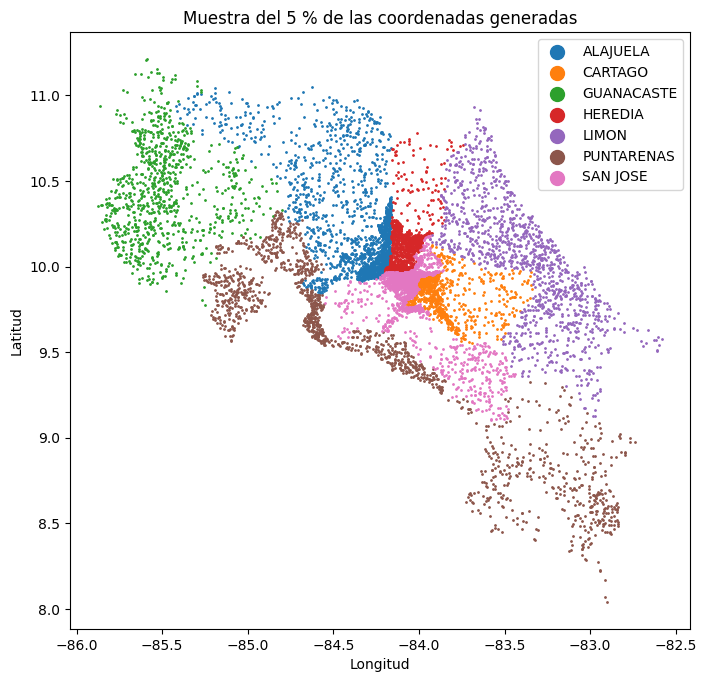

In [61]:
# sample toma una muestra aleatoria del 5 % para graficar; graficar 240 mil puntos sería lento.
muestra_mapa = oij_coordenadas.sample(fraction=0.05, seed=42).select("provincia", "latitud", "longitud").toPandas()

plt.figure(figsize=(8, 8))
for provincia in sorted(muestra_mapa["provincia"].unique()):
    puntos = muestra_mapa[muestra_mapa["provincia"] == provincia]
    plt.scatter(puntos["longitud"], puntos["latitud"], s=1, label=provincia)

plt.title("Muestra del 5 % de las coordenadas generadas")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.legend(markerscale=10)
plt.gca().set_aspect("equal")
plt.show()

El mapa reproduce la forma de Costa Rica y cada provincia ocupa su región. Las tres verificaciones
dan cero errores: todos los registros tienen una coordenada válida dentro de su cantón.

## 9. Integración de los conjuntos de datos

### 9.1 Llave y tipo de join

- **Llave:** el nombre normalizado del cantón (`clave_censo`). Es el nivel geográfico común a
  ambas fuentes: el OIJ no trae distrito y el censo sí trae cantón. La normalización y la tabla de
  equivalencias (sección 8.2) resuelven las diferencias de escritura, los cambios de nombre y los
  cantones creados después de 2011.
- **Tipo de join:** `left join`, con el OIJ a la izquierda. El OIJ es el conjunto principal (cada
  registro es un delito que se va a indexar en Solr) y el censo lo enriquece con los indicadores de
  su cantón. Con un `left join` ningún delito se pierde aunque no encuentre su cantón en el censo.
- **Relación:** muchos a uno. Cada delito tiene un solo cantón y cada cantón tiene muchos delitos,
  así que el join no debe duplicar registros. Para garantizarlo, se verifica que la llave sea única
  en el censo.

In [62]:
# La llave del censo se normaliza con la misma función que la del OIJ.
censo_claves = censo_limpio.withColumn("clave_censo", normalizar_texto(F.col("canton")))

print("Cantones del censo:", censo_claves.count())
print("Llaves distintas en el censo:", censo_claves.select("clave_censo").distinct().count())

# Cuántos cantones quedarían sin pareja sin la tabla de equivalencias y con ella.
print("Cantones del OIJ que no encuentran pareja en el censo:")
print("  Sin la tabla de equivalencias:", oij_claves.select("clave_oij").distinct().join(
    censo_claves.select(F.col("clave_censo").alias("clave_oij")), "clave_oij", "left_anti").count())
print("  Con la tabla de equivalencias:", oij_claves.select("clave_censo").distinct().join(
    censo_claves.select("clave_censo"), "clave_censo", "left_anti").count())

Cantones del censo: 81
Llaves distintas en el censo: 81
Cantones del OIJ que no encuentran pareja en el censo:
  Sin la tabla de equivalencias: 7
  Con la tabla de equivalencias: 0


### 9.2 Ejecución del join

In [63]:
# Columnas del censo que se agregan a cada delito. canton se renombra para no chocar con el del OIJ.
columnas_censo = [
    "clave_censo",
    F.col("canton").alias("canton_censo"),
    "poblacion_15_mas",
    "tasa_participacion",
    "tasa_ocupacion",
    "tasa_desempleo",
    "pct_inactiva",
    "relacion_dependencia",
    "pct_sector_primario",
    "pct_sector_secundario",
    "pct_sector_terciario",
    "economia_predominante",
    "nivel_desempleo",
]

registros_antes_join = oij_coordenadas.count()

# Left join muchos a uno: cada delito recibe los indicadores de su cantón.
# broadcast: el censo (81 filas) se copia a cada nodo, así Spark no tiene que redistribuir los 240 mil delitos.
integrado = oij_coordenadas.join(F.broadcast(censo_claves.select(columnas_censo)), "clave_censo", "left")
integrado.cache()

registros_despues_join = integrado.count()
# Registros cuyo cantón no encontró pareja: tendrían nulos en las columnas del censo.
registros_sin_pareja = integrado.filter(F.col("canton_censo").isNull()).count()

print("Registros antes del join:", registros_antes_join)
print("Registros después del join:", registros_despues_join)
print("Registros sin correspondencia en el censo:", registros_sin_pareja)

integrado.select(
    "id", "delito", "canton", "canton_censo", "tasa_desempleo", "economia_predominante", "nivel_desempleo"
).show(5, truncate=False)

Registros antes del join: 240683
Registros después del join: 240683
Registros sin correspondencia en el censo: 0
+----------------+-----------------+----------+------------+------------------+---------------------+---------------+
|id              |delito           |canton    |canton_censo|tasa_desempleo    |economia_predominante|nivel_desempleo|
+----------------+-----------------+----------+------------+------------------+---------------------+---------------+
|007260c9ecab9e80|ROBO DE VEHICULO |PUNTARENAS|Puntarenas  |3.734562575492395 |TERCIARIO            |ALTO           |
|0098b90ebc7d16ac|TACHA DE VEHICULO|GARABITO  |Garabito    |3.632913108309611 |TERCIARIO            |ALTO           |
|009fd2327301cf36|TACHA DE VEHICULO|OSA       |Osa         |2.9855044638571564|TERCIARIO            |MEDIO          |
|00d939eb1e000f7a|TACHA DE VEHICULO|SAN JOSE  |San José    |3.9342905550480562|TERCIARIO            |ALTO           |
|014a3c0a7415a2e1|ASALTO           |SIQUIRRES |Siquirres   |3

In [64]:
print("Cantones del OIJ asignados a otro cantón del censo:")
(
    integrado
    .filter(F.col("clave_oij") != F.col("clave_censo"))
    .groupBy("canton", "canton_censo")
    .count()
    .orderBy(F.desc("count"))
    .show(truncate=False)
)

Cantones del OIJ asignados a otro cantón del censo:
+-------------------+-------------------+-----+
|canton             |canton_censo       |count|
+-------------------+-------------------+-----+
|QUEPOS             |Aguirre            |3385 |
|VASQUEZ DE CORONADO|Vázquez de Coronado|1686 |
|PUERTO JIMENEZ     |Golfito            |507  |
|MONTEVERDE         |Puntarenas         |431  |
|SARCHI             |Valverde Vega      |292  |
|RIO CUARTO         |Grecia             |292  |
|LEON CORTES        |León Cortés Castro |176  |
+-------------------+-------------------+-----+



La cantidad de registros es la misma antes y después del join, y ningún registro quedó sin
correspondencia: la tabla de equivalencias resolvió todos los casos encontrados en la exploración.

Los registros de Río Cuarto, Puerto Jiménez y Monteverde reciben los indicadores del cantón del
que se separaron. Es una aproximación: en 2011 esos territorios formaban parte de esos cantones, así
que los indicadores del censo describen la zona a la que pertenecían en ese momento.

### 9.3 Tasa de delitos por habitante

Para comparar cantones de distinto tamaño se calcula la **tasa anual de delitos por cada 1000
habitantes de 15 años y más**:

$$
\text{tasa anual} = \frac{\text{delitos del cantón}}{\text{años del periodo}} \cdot \frac{1000}{\text{población de 15 años y más}}
$$

El periodo va del 1 de enero de 2019 a la fecha de corte de los datos, y se mide en años. Los
delitos se agrupan por cantón del censo (`clave_censo`), es decir, por territorio de 2011, para que
el numerador y la población del denominador describan el mismo territorio.

**Limitación:** la población es la del censo de 2011 y solo cuenta a las personas de 15 años y más.
La tasa no es una tasa oficial de criminalidad, pero sirve para **comparar** cantones entre sí,
porque todos se miden con la misma base.

In [65]:
# Duración del periodo en años: días entre el 1 de enero de 2019 y la fecha de corte, entre 365,25.
fecha_corte = integrado.agg(F.max("fecha")).first()[0]
dias_periodo = integrado.select(F.datediff(F.lit(fecha_corte), F.lit("2019-01-01")).alias("dias")).first()["dias"] + 1
anios_periodo = dias_periodo / 365.25
print("Años del periodo:", round(anios_periodo, 3))

# Tasa anual por cada 1000 habitantes = delitos / años / población * 1000.
tasas_canton = (
    integrado
    .groupBy("clave_censo", "canton_censo", "poblacion_15_mas")
    .count()
    .withColumnRenamed("count", "delitos")
    .withColumn("tasa_delitos_anual_1000", F.round(F.col("delitos") / F.lit(anios_periodo) * 1000 / F.col("poblacion_15_mas"), 3))
)

integrado = integrado.join(tasas_canton.select("clave_censo", "tasa_delitos_anual_1000"), "clave_censo", "left")
integrado.cache()

print("Cantones con mayor tasa:")
tasas_canton.orderBy(F.desc("tasa_delitos_anual_1000")).show(8)
print("Cantones con menor tasa:")
tasas_canton.orderBy("tasa_delitos_anual_1000").show(5)

Años del periodo: 7.893
Cantones con mayor tasa:
+-------------+-------------+----------------+-------+-----------------------+
|  clave_censo| canton_censo|poblacion_15_mas|delitos|tasa_delitos_anual_1000|
+-------------+-------------+----------------+-------+-----------------------+
|     GARABITO|     Garabito|           12244|   5242|                  54.24|
|     SAN JOSE|     San José|          225856|  57595|                 32.307|
|      AGUIRRE|      Aguirre|           19804|   3385|                 21.655|
|    TALAMANCA|    Talamanca|           19899|   3204|                 20.399|
|MONTES DE OCA|Montes de Oca|           41561|   5404|                 16.473|
|          OSA|          Osa|           21458|   2717|                 16.042|
|      LIBERIA|      Liberia|           45580|   5589|                 15.535|
|      PARRITA|      Parrita|           11857|   1448|                 15.472|
+-------------+-------------+----------------+-------+-----------------------+
onl

### 9.4 Relación entre los indicadores económicos y la criminalidad

Con los datos integrados se puede responder la pregunta del proyecto. Se trabaja a nivel de cantón
(81 territorios del censo) y se calcula la **correlación de Pearson** entre la tasa de delitos y
cada indicador económico. La correlación va de -1 a 1: un valor positivo significa que, cuando el
indicador sube, la tasa de delitos tiende a subir; uno negativo, que tiende a bajar; y uno cercano a
0, que no hay relación lineal.

In [66]:
# Un registro por cantón, con su tasa de delitos y sus indicadores económicos.
indicadores_cantonales = (
    tasas_canton
    .join(censo_claves.drop("canton", "provincia", "poblacion_15_mas"), "clave_censo")
)

indicadores_a_comparar = [
    "tasa_desempleo",
    "tasa_participacion",
    "tasa_ocupacion",
    "relacion_dependencia",
    "pct_sector_primario",
    "pct_sector_secundario",
    "pct_sector_terciario",
]

# stat.corr calcula la correlación de Pearson entre dos columnas numéricas.
filas_correlacion = []
for indicador in indicadores_a_comparar:
    correlacion = indicadores_cantonales.stat.corr("tasa_delitos_anual_1000", indicador)
    filas_correlacion.append((indicador, round(correlacion, 3)))

correlaciones = spark.createDataFrame(filas_correlacion, ["indicador", "correlacion_con_tasa"])
correlaciones.orderBy(F.desc(F.abs(F.col("correlacion_con_tasa")))).show(truncate=False)

+---------------------+--------------------+
|indicador            |correlacion_con_tasa|
+---------------------+--------------------+
|tasa_desempleo       |0.267               |
|tasa_participacion   |0.233               |
|pct_sector_terciario |0.222               |
|tasa_ocupacion       |0.204               |
|pct_sector_primario  |-0.145              |
|pct_sector_secundario|-0.112              |
|relacion_dependencia |-0.11               |
+---------------------+--------------------+



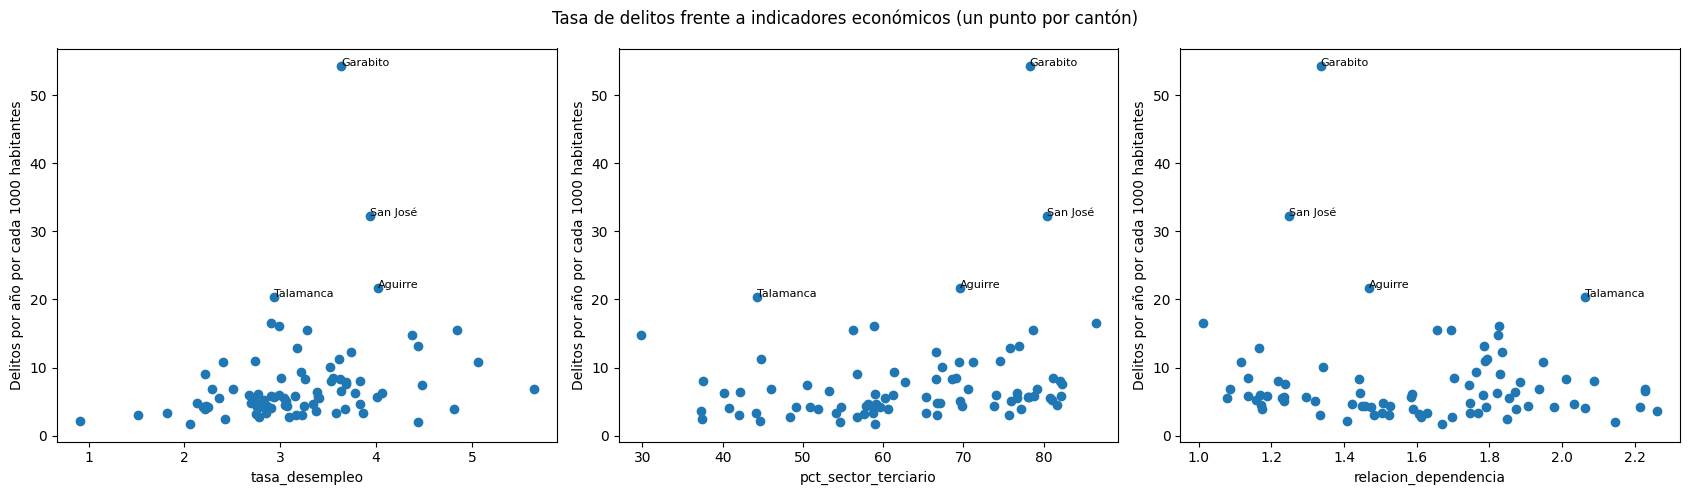

In [67]:
# Diagramas de dispersión con un punto por cantón; se etiquetan los 4 cantones con mayor tasa.
datos_grafico = indicadores_cantonales.select(
    "canton_censo", "tasa_delitos_anual_1000", "tasa_desempleo", "pct_sector_terciario", "relacion_dependencia"
).toPandas()

figura, ejes = plt.subplots(1, 3, figsize=(17, 5))
ejes_x = ["tasa_desempleo", "pct_sector_terciario", "relacion_dependencia"]

for posicion in range(len(ejes_x)):
    eje = ejes[posicion]
    eje.scatter(datos_grafico[ejes_x[posicion]], datos_grafico["tasa_delitos_anual_1000"])
    eje.set_xlabel(ejes_x[posicion])
    eje.set_ylabel("Delitos por año por cada 1000 habitantes")

    mas_altos = datos_grafico.sort_values("tasa_delitos_anual_1000", ascending=False).head(4)
    for indice in mas_altos.index:
        eje.annotate(
            mas_altos.loc[indice, "canton_censo"],
            (mas_altos.loc[indice, ejes_x[posicion]], mas_altos.loc[indice, "tasa_delitos_anual_1000"]),
            fontsize=8,
        )

plt.suptitle("Tasa de delitos frente a indicadores económicos (un punto por cantón)")
plt.tight_layout()
plt.show()

In [68]:
# Se compara la tasa entre grupos de cantones. También se muestra la mediana porque es menos
# sensible a valores extremos como Garabito.
print("Tasa promedio de delitos según la economía predominante:")
(
    indicadores_cantonales
    .groupBy("economia_predominante")
    .agg(
        F.count("*").alias("cantones"),
        F.round(F.avg("tasa_delitos_anual_1000"), 2).alias("tasa_promedio"),
        F.round(F.expr("percentile_approx(tasa_delitos_anual_1000, 0.5)"), 2).alias("tasa_mediana"),
    )
    .show()
)

print("Tasa promedio de delitos según el nivel de desempleo:")
(
    indicadores_cantonales
    .groupBy("nivel_desempleo")
    .agg(
        F.count("*").alias("cantones"),
        F.round(F.avg("tasa_delitos_anual_1000"), 2).alias("tasa_promedio"),
        F.round(F.expr("percentile_approx(tasa_delitos_anual_1000, 0.5)"), 2).alias("tasa_mediana"),
    )
    .orderBy(F.when(F.col("nivel_desempleo") == "BAJO", 1).when(F.col("nivel_desempleo") == "MEDIO", 2).otherwise(3))
    .show()
)

Tasa promedio de delitos según la economía predominante:
+---------------------+--------+-------------+------------+
|economia_predominante|cantones|tasa_promedio|tasa_mediana|
+---------------------+--------+-------------+------------+
|            TERCIARIO|      70|         7.81|        5.67|
|             PRIMARIO|      11|         7.59|        6.28|
+---------------------+--------+-------------+------------+

Tasa promedio de delitos según el nivel de desempleo:
+---------------+--------+-------------+------------+
|nivel_desempleo|cantones|tasa_promedio|tasa_mediana|
+---------------+--------+-------------+------------+
|           BAJO|      27|         4.93|         4.3|
|          MEDIO|      27|         7.51|        5.67|
|           ALTO|      27|         10.9|        7.84|
+---------------+--------+-------------+------------+



In [69]:
# Porcentaje de cada tipo de delito dentro de cada grupo de economía:
# - sum(...).over(Window.partitionBy(...)) calcula el total del grupo sin colapsar las filas.
# - pivot convierte los valores de economia_predominante en columnas.
composicion = (
    integrado
    .groupBy("economia_predominante", "delito")
    .count()
    .withColumn(
        "porcentaje",
        F.round(F.col("count") / F.sum("count").over(Window.partitionBy("economia_predominante")) * 100, 2),
    )
    .groupBy("delito")
    .pivot("economia_predominante")
    .agg(F.first("porcentaje"))
    .orderBy("delito")
)

print("Porcentaje de cada tipo de delito según la economía predominante del cantón:")
composicion.show(truncate=False)

Porcentaje de cada tipo de delito según la economía predominante del cantón:
+-----------------+--------+---------+
|delito           |PRIMARIO|TERCIARIO|
+-----------------+--------+---------+
|ASALTO           |36.25   |33.12    |
|HOMICIDIO        |4.6     |2.22     |
|HURTO            |30.13   |32.63    |
|ROBO             |7.09    |4.44     |
|ROBO DE VEHICULO |15.41   |14.62    |
|TACHA DE VEHICULO|6.51    |12.98    |
+-----------------+--------+---------+



#### Interpretación

**1. Hay una relación entre desempleo y criminalidad, pero es moderada.** El desempleo es el
indicador con la correlación más alta con la tasa de delitos (0,27), y la relación se ve con
claridad al agrupar los cantones por nivel de desempleo: la tasa mediana sube de 4,3 delitos por
cada 1000 habitantes al año en los cantones de desempleo bajo, a 5,7 en los de desempleo medio y a
7,8 en los de desempleo alto. Es decir, los cantones con más desempleo tienen, en promedio, casi el
doble de criminalidad que los de menos desempleo. Aun así, una correlación de 0,27 indica que el
desempleo explica solo una parte de la variación: hay otros factores que influyen.

**2. El turismo distorsiona la tasa.** Los cantones con las tasas más altas son Garabito (Jacó),
San José, Aguirre (Quepos), Talamanca, Osa, Liberia y Parrita. Varios son destinos turísticos: en
ellos hay muchas más personas presentes (turistas, trabajadores que viajan desde otros cantones) que
las que cuenta el censo como residentes, así que el denominador subestima la población real y la
tasa queda inflada. San José tiene el mismo efecto por la población que llega cada día a trabajar.

**3. La economía predominante no cambia cuánto delito hay, pero sí qué tipo de delito.** Los
cantones agrícolas (sector primario) y los de servicios (sector terciario) tienen tasas parecidas
(mediana de 6,3 frente a 5,7). Sin embargo, la composición es distinta:

- En los cantones agrícolas, los **homicidios** pesan el doble (4,6 % frente a 2,2 % de los delitos)
  y los robos también son más frecuentes (7,1 % frente a 4,4 %).
- En los cantones de servicios, la **tacha de vehículos** pesa el doble (13,0 % frente a 6,5 %), lo
  que concuerda con zonas urbanas y turísticas con más vehículos estacionados.

**Limitaciones:** los indicadores económicos son de 2011 y los delitos de 2019-2026; la relación es
una correlación entre cantones y no permite concluir causalidad; y la tasa usa solo la población
residente de 15 años y más.

## 10. Detección de anomalías

### 10.1 Datos para la detección

Un delito individual no es "anómalo" por sí mismo: lo interesante es detectar **cantones y meses
con un comportamiento delictivo fuera de lo normal**. Por eso los datos se agregan por cantón del
censo y por mes, y para cada combinación se calcula la tasa mensual de cada tipo de delito por cada
10 000 habitantes de 15 años y más. Usar tasas, y no conteos, evita que los cantones grandes
aparezcan como anómalos solo por su tamaño.

Hay dos detalles importantes:

- Los meses en que un cantón no tuvo delitos de algún tipo no aparecen en los datos. Para que
  cuenten como cero, se construyen todas las combinaciones posibles de cantón y mes con un
  `crossJoin` y luego se rellenan los faltantes con cero.
- Noviembre de 2026 está incompleto (los datos llegan hasta el día 22), así que se excluye: con
  menos días, todas sus tasas serían bajas y el mes aparecería como anómalo de forma artificial.

In [70]:
# Cada tupla: (valor en los datos, nombre corto para las columnas).
tipos_delito = [
    ("ASALTO", "asalto"),
    ("HURTO", "hurto"),
    ("ROBO", "robo"),
    ("ROBO DE VEHICULO", "robo_vehiculo"),
    ("TACHA DE VEHICULO", "tacha_vehiculo"),
    ("HOMICIDIO", "homicidio"),
]

integrado = integrado.withColumn("periodo", F.date_format("fecha", "yyyy-MM"))

# Noviembre de 2026 se excluye por estar incompleto.
ultimo_mes_completo = "2026-10"

# pivot crea una columna por tipo de delito, con la cantidad de casos de cada cantón y mes.
conteos_mensuales = (
    integrado
    .filter(F.col("periodo") <= ultimo_mes_completo)
    .groupBy("clave_censo", "periodo")
    .pivot("delito", [tipo[0] for tipo in tipos_delito])
    .count()
)

for tipo in tipos_delito:
    conteos_mensuales = conteos_mensuales.withColumnRenamed(tipo[0], "cantidad_" + tipo[1])

# crossJoin produce todas las combinaciones cantón × mes (81 × 94).
# Luego el left join trae los conteos, y fillna(0) pone cero donde no hubo delitos.
todos_los_periodos = integrado.filter(F.col("periodo") <= ultimo_mes_completo).select("periodo").distinct()
todos_los_cantones = censo_claves.select("clave_censo", F.col("canton").alias("canton_censo"), "poblacion_15_mas")

mensual = (
    todos_los_cantones
    .crossJoin(todos_los_periodos)
    .join(conteos_mensuales, ["clave_censo", "periodo"], "left")
    .fillna(0)
)

# Tasa mensual por cada 10 000 habitantes, para cada tipo de delito.
columnas_tasas = []
for tipo in tipos_delito:
    columna_tasa = "tasa_" + tipo[1]
    mensual = mensual.withColumn(
        columna_tasa, F.col("cantidad_" + tipo[1]) * 10000 / F.col("poblacion_15_mas")
    )
    columnas_tasas.append(columna_tasa)

mensual = mensual.withColumn("id_mensual", F.concat_ws("_", "clave_censo", "periodo"))
mensual.cache()

print("Combinaciones cantón-mes:", mensual.count())
print("Cantones:", mensual.select("clave_censo").distinct().count())
print("Meses:", mensual.select("periodo").distinct().count())
mensual.select("canton_censo", "periodo", *columnas_tasas).show(5)

Combinaciones cantón-mes: 7614
Cantones: 81
Meses: 94
+-------------+-------+------------------+------------------+------------------+------------------+-------------------+-------------------+
| canton_censo|periodo|       tasa_asalto|        tasa_hurto|         tasa_robo|tasa_robo_vehiculo|tasa_tacha_vehiculo|     tasa_homicidio|
+-------------+-------+------------------+------------------+------------------+------------------+-------------------+-------------------+
|Pérez Zeledón|2023-08|1.1203226529240422|2.4443403336524554|0.6110850834131138|0.4073900556087426| 0.3055425417065569| 0.2036950278043713|
|     Alajuela|2023-08| 2.615344379317241|2.3589380676194724|0.5128126233955375| 2.820469428675456| 1.3845940831679513|0.15384378701866125|
|      La Cruz|2022-04|3.8150465435678313|1.5260186174271326|0.7630093087135663|               0.0|                0.0|                0.0|
|Santa Bárbara|2026-06|0.3610760064993681|0.7221520129987362|               0.0|1.8053800324968405|       

### 10.2 Estandarización

Las seis tasas tienen escalas muy distintas: hay muchos más hurtos que homicidios. Si no se
estandarizan, los métodos basados en distancias (K-Means y PCA) solo "verían" los delitos
frecuentes. `StandardScaler` transforma cada variable para que tenga media 0 y desviación estándar
1:

$$
z = \frac{x - \mu}{\sigma}
$$

In [71]:
# Herramientas de Spark MLlib para preparar los datos y aplicar los modelos.
from pyspark.ml.feature import VectorAssembler, StandardScaler, PCA
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.sql.types import DoubleType

# VectorAssembler junta las seis tasas en una sola columna de tipo vector,
# que es el formato que esperan los modelos de MLlib.
ensamblador = VectorAssembler(inputCols=columnas_tasas, outputCol="caracteristicas")
mensual_vector = ensamblador.transform(mensual)

# StandardScaler: withMean resta la media y withStd divide entre la desviación estándar.
# fit calcula esas estadísticas y transform las aplica a los datos.
escalador = StandardScaler(inputCol="caracteristicas", outputCol="caracteristicas_escaladas", withMean=True, withStd=True)
modelo_escalador = escalador.fit(mensual_vector)
mensual_escalado = modelo_escalador.transform(mensual_vector)
mensual_escalado.cache()

mensual_escalado.select("canton_censo", "periodo", "caracteristicas_escaladas").show(3, truncate=False)

+-------------+-------+---------------------------------------------------------------------------------------------------------------------------+
|canton_censo |periodo|caracteristicas_escaladas                                                                                                  |
+-------------+-------+---------------------------------------------------------------------------------------------------------------------------+
|Pérez Zeledón|2023-08|[-0.28153632692273955,0.08315010284969544,0.29750351576606243,-0.6165984819803145,-0.27346779047065667,0.07355694653018786]|
|Alajuela     |2023-08|[0.40828817444063126,0.05499507816239923,0.16378633118407548,1.800457593908467,0.16038922153988774,-0.05562016417474152]   |
|La Cruz      |2022-04|[0.9618479874042196,-0.21959795984478458,0.5042234826147868,-1.0246599076243341,-0.39631806137373254,-0.454268133488112]   |
+-------------+-------+-----------------------------------------------------------------------------------------

### 10.3 Método 1: Z-score

**Idea:** para cada variable se calcula cuántas desviaciones estándar se aleja el valor de la media.
Una combinación cantón-mes se marca como anómala si **alguna** de sus seis tasas tiene un valor
absoluto de $z$ mayor que 3. En una distribución normal, solo el 0,3 % de los valores supera ese
umbral.

**Fortaleza:** es simple e interpretable: dice exactamente qué tipo de delito se salió de lo normal.
**Debilidad:** revisa cada variable por separado, así que no detecta combinaciones raras de valores
que individualmente son normales.

In [72]:
# Media y desviación estándar de cada tasa, calculadas en una sola pasada sobre los datos.
estadisticas = mensual.select(
    *[F.mean(columna).alias("media_" + columna) for columna in columnas_tasas],
    *[F.stddev(columna).alias("desviacion_" + columna) for columna in columnas_tasas],
).first()

# Para cada tasa: z = (valor - media) / desviación. Se guardan los valores absolutos para tomar el máximo.
resultado_z = mensual
columnas_z = []

for columna in columnas_tasas:
    columna_z = "z_" + columna
    resultado_z = resultado_z.withColumn(
        columna_z,
        (F.col(columna) - F.lit(estadisticas["media_" + columna])) / F.lit(estadisticas["desviacion_" + columna]),
    )
    columnas_z.append(F.abs(F.col(columna_z)))

resultado_z = (
    resultado_z
    # greatest devuelve el mayor |z| de las seis tasas; si supera 3, la combinación es anómala.
    .withColumn("z_maximo", F.greatest(*columnas_z))
    .withColumn("anomalia_zscore", (F.col("z_maximo") > 3.0).cast("int"))
)

print("Anomalías Z-score:", resultado_z.filter(F.col("anomalia_zscore") == 1).count())
resultado_z.orderBy(F.desc("z_maximo")).select("canton_censo", "periodo", "z_maximo", *columnas_tasas).show(8)

Anomalías Z-score: 601
+------------+-------+------------------+------------------+------------------+------------------+------------------+-------------------+------------------+
|canton_censo|periodo|          z_maximo|       tasa_asalto|        tasa_hurto|         tasa_robo|tasa_robo_vehiculo|tasa_tacha_vehiculo|    tasa_homicidio|
+------------+-------+------------------+------------------+------------------+------------------+------------------+-------------------+------------------+
|  Turrubares|2022-12| 24.62438335776609|               0.0|2.4195499637067504|               0.0|               0.0|                0.0| 9.678199854827001|
|    Garabito|2025-08|20.948598780285085| 6.533812479581836| 16.33453119895459|               0.0| 3.266906239790918|  53.08722639660242|               0.0|
|    Garabito|2026-01|19.635065436183005|4.0836327997386475| 8.983992159425025| 7.350539039529566| 3.266906239790918|   49.8203201568115|0.8167265599477295|
|    Garabito|2025-02|18.6090802777

### 10.4 Método 2: distancia al centroide de K-Means

**Idea:** K-Means agrupa las combinaciones cantón-mes en $k$ grupos de comportamiento parecido.
Cada grupo tiene un centroide (su comportamiento "típico"). Una combinación que queda muy lejos del
centroide de su grupo no se parece a ningún patrón común, y se considera anómala.

**Elección de $k$:** se prueban valores de 2 a 8 y se elige el que tiene el mayor **coeficiente de
silueta**, que mide qué tan bien separados quedan los grupos (cerca de 1 es mejor).

In [73]:
# Se entrena K-Means con k de 2 a 8 y se mide el coeficiente de silueta de cada uno.
evaluador = ClusteringEvaluator(featuresCol="caracteristicas_escaladas", metricName="silhouette")
siluetas = []

for k in range(2, 9):
    modelo_prueba = KMeans(featuresCol="caracteristicas_escaladas", k=k, seed=42).fit(mensual_escalado)
    silueta = evaluador.evaluate(modelo_prueba.transform(mensual_escalado))
    siluetas.append((k, round(silueta, 4)))
    print("k =", k, " silueta =", round(silueta, 4))

# Búsqueda del k con la mayor silueta.
mejor_k = siluetas[0][0]
mejor_silueta = siluetas[0][1]
for par in siluetas:
    if par[1] > mejor_silueta:
        mejor_k = par[0]
        mejor_silueta = par[1]

print("k elegido:", mejor_k)

k = 2  silueta = 0.8235
k = 3  silueta = 0.6186
k = 4  silueta = 0.3359
k = 5  silueta = 0.352
k = 6  silueta = 0.3796
k = 7  silueta = 0.3654
k = 8  silueta = 0.3774
k elegido: 2


**Umbral:** la distancia al centroide no tiene un umbral natural como el $z > 3$. Siguiendo lo visto
en clase, se usa un percentil: se marca como anómalo el **3 %** de las combinaciones con mayor
distancia. Se elige un valor bajo porque una anomalía, por definición, debe ser poco frecuente, y
se usa el mismo 3 % en PCA para que esos dos métodos sean comparables entre sí.

In [74]:
# Modelo final con el mejor k. clusterCenters devuelve el centroide de cada grupo.
modelo_kmeans = KMeans(featuresCol="caracteristicas_escaladas", predictionCol="grupo", k=mejor_k, seed=42).fit(mensual_escalado)
centroides = modelo_kmeans.clusterCenters()


# Distancia euclidiana entre el punto y el centroide de su grupo:
# raíz cuadrada de la suma de las diferencias al cuadrado en cada dimensión.
def distancia_al_centroide(vector, grupo):
    centro = centroides[int(grupo)]
    suma = 0.0
    for posicion in range(len(centro)):
        diferencia = float(vector[posicion]) - float(centro[posicion])
        suma = suma + diferencia * diferencia
    return float(suma ** 0.5)


# F.udf convierte la función de Python en una función que Spark puede aplicar a cada fila.
distancia_udf = F.udf(distancia_al_centroide, DoubleType())

resultado_kmeans = (
    modelo_kmeans.transform(mensual_escalado)
    .withColumn("distancia_centroide", distancia_udf(F.col("caracteristicas_escaladas"), F.col("grupo")))
)

# Umbral: percentil 97 de la distancia. El 3 % más lejano se marca como anomalía.
umbral_kmeans = resultado_kmeans.approxQuantile("distancia_centroide", [0.97], 0.0)[0]
resultado_kmeans = resultado_kmeans.withColumn(
    "anomalia_kmeans", (F.col("distancia_centroide") >= F.lit(umbral_kmeans)).cast("int")
)

print("Umbral de distancia:", round(umbral_kmeans, 3))
print("Anomalías K-Means:", resultado_kmeans.filter(F.col("anomalia_kmeans") == 1).count())
print("Tamaño de cada grupo:")
resultado_kmeans.groupBy("grupo").count().orderBy("grupo").show()
resultado_kmeans.orderBy(F.desc("distancia_centroide")).select("canton_censo", "periodo", "grupo", "distancia_centroide").show(8)

Umbral de distancia: 4.665
Anomalías K-Means: 229
Tamaño de cada grupo:
+-----+-----+
|grupo|count|
+-----+-----+
|    0| 7123|
|    1|  491|
+-----+-----+

+------------+-------+-----+-------------------+
|canton_censo|periodo|grupo|distancia_centroide|
+------------+-------+-----+-------------------+
|  Turrubares|2022-12|    1| 24.204131628779837|
|    Garabito|2026-01|    1| 19.567194034413266|
|    Garabito|2025-08|    1|  19.30249504882718|
|    Garabito|2025-02|    1|  17.73625102151679|
|    Garabito|2025-12|    1|  17.55996456320117|
|    Garabito|2019-07|    1|   16.5765610736968|
|   San Mateo|2026-03|    1| 15.614176198080823|
|    Garabito|2019-08|    1| 15.296402126042656|
+------------+-------+-----+-------------------+
only showing top 8 rows


### 10.5 Método 3: error de reconstrucción con PCA

**Idea:** PCA encuentra las direcciones (componentes principales) que explican la mayor parte de la
variación de los datos. Si se proyecta cada combinación sobre pocas componentes y luego se
reconstruye, los datos "normales" se reconstruyen bien, porque siguen los patrones generales. Las
anomalías no siguen esos patrones y quedan con un **error de reconstrucción** alto.

**Cantidad de componentes:** se usan las mínimas necesarias para explicar al menos el 80 % de la
varianza.

In [75]:
# PCA con todas las componentes, solo para ver cuánta varianza explica cada una.
modelo_pca_completo = PCA(k=len(columnas_tasas), inputCol="caracteristicas_escaladas", outputCol="componentes").fit(mensual_escalado)
varianza = modelo_pca_completo.explainedVariance.toArray()

# Se suman las varianzas hasta llegar al 80 %; esa es la cantidad de componentes a usar.
acumulada = 0.0
componentes_elegidas = 0
for posicion in range(len(varianza)):
    acumulada = acumulada + varianza[posicion]
    print("Componente", posicion + 1, ": varianza", round(varianza[posicion], 4), " acumulada", round(acumulada, 4))
    if componentes_elegidas == 0 and acumulada >= 0.8:
        componentes_elegidas = posicion + 1

print("Componentes elegidas:", componentes_elegidas)

Componente 1 : varianza 0.3879  acumulada 0.3879
Componente 2 : varianza 0.1609  acumulada 0.5488
Componente 3 : varianza 0.1482  acumulada 0.697
Componente 4 : varianza 0.1252  acumulada 0.8222
Componente 5 : varianza 0.1114  acumulada 0.9336
Componente 6 : varianza 0.0664  acumulada 1.0
Componentes elegidas: 4


In [76]:
# Modelo final. pc es la matriz de componentes: cada columna es una componente principal.
modelo_pca = PCA(k=componentes_elegidas, inputCol="caracteristicas_escaladas", outputCol="componentes").fit(mensual_escalado)
matriz_componentes = modelo_pca.pc.toArray()


# Reconstrucción: matriz de componentes @ proyección (multiplicación de matrices).
# El error es la distancia entre el vector original y el reconstruido.
def error_reconstruccion(vector_escalado, componentes):
    original = np.array(vector_escalado)
    reconstruido = matriz_componentes @ np.array(componentes)
    return float(np.linalg.norm(original - reconstruido))


error_udf = F.udf(error_reconstruccion, DoubleType())

resultado_pca = (
    modelo_pca.transform(mensual_escalado)
    .withColumn("error_reconstruccion", error_udf(F.col("caracteristicas_escaladas"), F.col("componentes")))
)

# Mismo criterio que en K-Means: el 3 % con mayor error se marca como anomalía.
umbral_pca = resultado_pca.approxQuantile("error_reconstruccion", [0.97], 0.0)[0]
resultado_pca = resultado_pca.withColumn(
    "anomalia_pca", (F.col("error_reconstruccion") >= F.lit(umbral_pca)).cast("int")
)

print("Umbral de error:", round(umbral_pca, 3))
print("Anomalías PCA:", resultado_pca.filter(F.col("anomalia_pca") == 1).count())
resultado_pca.orderBy(F.desc("error_reconstruccion")).select("canton_censo", "periodo", "error_reconstruccion").show(8)

Umbral de error: 2.334
Anomalías PCA: 229
+------------+-------+--------------------+
|canton_censo|periodo|error_reconstruccion|
+------------+-------+--------------------+
|    Garabito|2025-08|  15.549322284242994|
|    Garabito|2026-01|  12.856910096169495|
|    Garabito|2025-12|  12.758339190388373|
|    Garabito|2023-12|  10.070819044502475|
|    Garabito|2025-11|   9.929194673394038|
|    Garabito|2019-08|   9.857018547286614|
|    Garabito|2026-05|   9.464762110618139|
|    Garabito|2026-04|    9.44640418128705|
+------------+-------+--------------------+
only showing top 8 rows


### 10.6 Comparación de los métodos

In [77]:
# Se juntan los resultados de los tres métodos por id_mensual.
# cantidad_metodos (de 0 a 3) indica cuántos métodos marcaron cada combinación.
comparacion = (
    resultado_z.select("id_mensual", "clave_censo", "canton_censo", "periodo", "z_maximo", "anomalia_zscore", *columnas_tasas)
    .join(resultado_kmeans.select("id_mensual", "distancia_centroide", "anomalia_kmeans"), "id_mensual")
    .join(resultado_pca.select("id_mensual", "error_reconstruccion", "anomalia_pca"), "id_mensual")
    .withColumn("cantidad_metodos", F.col("anomalia_zscore") + F.col("anomalia_kmeans") + F.col("anomalia_pca"))
)
comparacion.cache()

total_mensual = comparacion.count()
filas_resumen = []
for nombre, columna in [("Z-score", "anomalia_zscore"), ("K-Means", "anomalia_kmeans"), ("PCA", "anomalia_pca")]:
    cantidad = comparacion.filter(F.col(columna) == 1).count()
    filas_resumen.append((nombre, cantidad, round(cantidad / total_mensual * 100, 2)))

spark.createDataFrame(filas_resumen, ["metodo", "anomalias", "porcentaje"]).show()

print("Cantidad de métodos que marcan cada combinación:")
comparacion.groupBy("cantidad_metodos").count().orderBy("cantidad_metodos").show()

+-------+---------+----------+
| metodo|anomalias|porcentaje|
+-------+---------+----------+
|Z-score|      601|      7.89|
|K-Means|      229|      3.01|
|    PCA|      229|      3.01|
+-------+---------+----------+

Cantidad de métodos que marcan cada combinación:
+----------------+-----+
|cantidad_metodos|count|
+----------------+-----+
|               0| 6998|
|               1|  299|
|               2|  191|
|               3|  126|
+----------------+-----+



Para medir qué tanto coinciden dos métodos se usa el **índice de Jaccard**: la cantidad de
anomalías que marcan ambos dividida entre la cantidad que marca al menos uno. Vale 1 si marcan
exactamente lo mismo y 0 si no coinciden en nada.

In [78]:
# Índice de Jaccard = marcadas por ambos / marcadas por al menos uno.
pares = [
    ("Z-score", "anomalia_zscore", "K-Means", "anomalia_kmeans"),
    ("Z-score", "anomalia_zscore", "PCA", "anomalia_pca"),
    ("K-Means", "anomalia_kmeans", "PCA", "anomalia_pca"),
]

filas_jaccard = []
for par in pares:
    ambos = comparacion.filter((F.col(par[1]) == 1) & (F.col(par[3]) == 1)).count()
    alguno = comparacion.filter((F.col(par[1]) == 1) | (F.col(par[3]) == 1)).count()
    filas_jaccard.append((par[0] + " y " + par[2], ambos, alguno, round(ambos / alguno, 3)))

spark.createDataFrame(filas_jaccard, ["metodos", "marcadas_por_ambos", "marcadas_por_alguno", "jaccard"]).show(truncate=False)

+-----------------+------------------+-------------------+-------+
|metodos          |marcadas_por_ambos|marcadas_por_alguno|jaccard|
+-----------------+------------------+-------------------+-------+
|Z-score y K-Means|229               |601                |0.381  |
|Z-score y PCA    |214               |616                |0.347  |
|K-Means y PCA    |126               |332                |0.38   |
+-----------------+------------------+-------------------+-------+



In [79]:
# Anomalías en las que coinciden los tres métodos, y cantones con más meses anómalos.
print("Combinaciones marcadas por los tres métodos (las anomalías más robustas):")
(
    comparacion
    .filter(F.col("cantidad_metodos") == 3)
    .orderBy(F.desc("z_maximo"))
    .select("canton_censo", "periodo", F.round("z_maximo", 2).alias("z_maximo"), *[F.round(c, 2).alias(c) for c in columnas_tasas])
    .show(15, truncate=False)
)

print("Cantones con más meses anómalos (marcados por al menos dos métodos):")
(
    comparacion
    .filter(F.col("cantidad_metodos") >= 2)
    .groupBy("canton_censo")
    .count()
    .withColumnRenamed("count", "meses_anomalos")
    .orderBy(F.desc("meses_anomalos"))
    .show(10)
)

Combinaciones marcadas por los tres métodos (las anomalías más robustas):
+------------+-------+--------+-----------+----------+---------+------------------+-------------------+--------------+
|canton_censo|periodo|z_maximo|tasa_asalto|tasa_hurto|tasa_robo|tasa_robo_vehiculo|tasa_tacha_vehiculo|tasa_homicidio|
+------------+-------+--------+-----------+----------+---------+------------------+-------------------+--------------+
|Turrubares  |2022-12|24.62   |0.0        |2.42      |0.0      |0.0               |0.0                |9.68          |
|Garabito    |2025-08|20.95   |6.53       |16.33     |0.0      |3.27              |53.09              |0.0           |
|Garabito    |2026-01|19.64   |4.08       |8.98      |7.35     |3.27              |49.82              |0.82          |
|Garabito    |2025-12|18.32   |4.08       |5.72      |5.72     |3.27              |46.55              |0.82          |
|Garabito    |2019-08|16.35   |11.43      |22.05     |2.45     |1.63              |41.65     

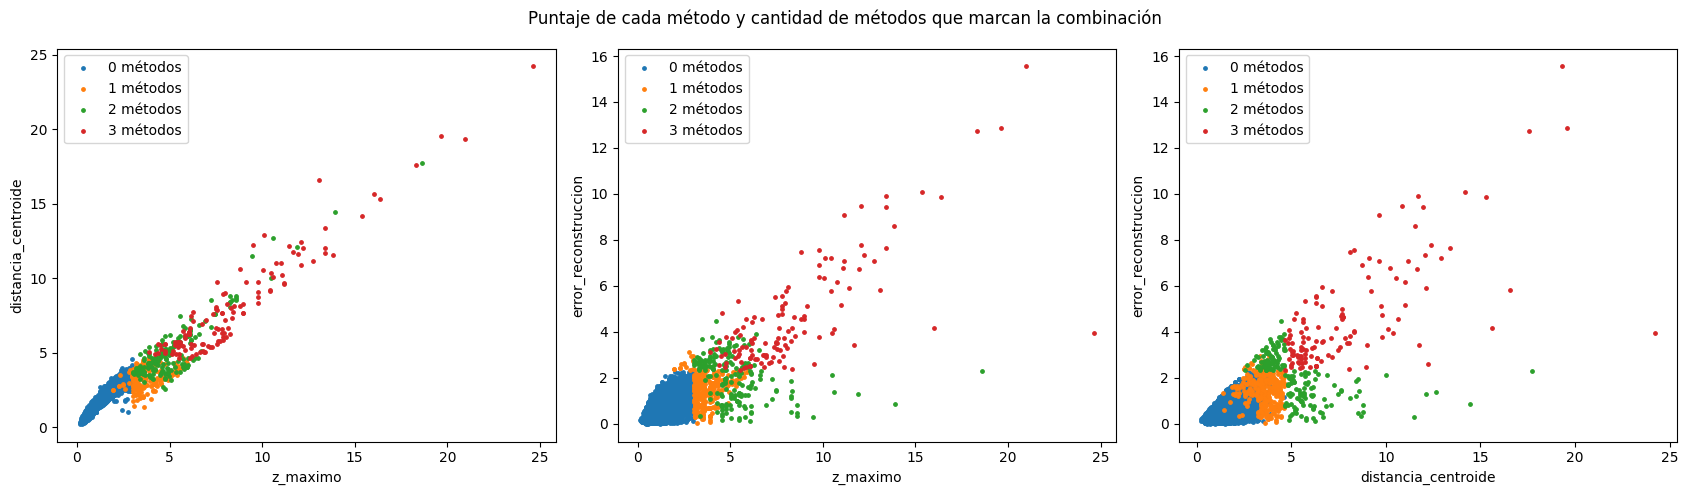

In [80]:
# Puntaje de cada par de métodos, con cada punto coloreado según cuántos métodos lo marcan.
datos_metodos = comparacion.select("z_maximo", "distancia_centroide", "error_reconstruccion", "cantidad_metodos").toPandas()

figura, ejes = plt.subplots(1, 3, figsize=(17, 5))
pares_grafico = [
    ("z_maximo", "distancia_centroide"),
    ("z_maximo", "error_reconstruccion"),
    ("distancia_centroide", "error_reconstruccion"),
]

for posicion in range(len(pares_grafico)):
    eje = ejes[posicion]
    x = pares_grafico[posicion][0]
    y = pares_grafico[posicion][1]
    for cantidad in [0, 1, 2, 3]:
        puntos = datos_metodos[datos_metodos["cantidad_metodos"] == cantidad]
        eje.scatter(puntos[x], puntos[y], s=6, label=str(cantidad) + " métodos")
    eje.set_xlabel(x)
    eje.set_ylabel(y)
    eje.legend()

plt.suptitle("Puntaje de cada método y cantidad de métodos que marcan la combinación")
plt.tight_layout()
plt.show()

#### Interpretación de los resultados

**1. El Z-score marca muchas más anomalías que los otros dos métodos (7,9 % frente a 3 %).** El
umbral $|z| > 3$ supone que los datos siguen una distribución normal, donde solo el 0,3 % de los
valores lo supera. Las tasas mensuales no cumplen ese supuesto: la mayoría de los cantones tiene
pocos delitos de cada tipo por mes (muchos ceros), y unos pocos tienen valores muy altos, así que la
distribución está muy sesgada hacia la derecha. Además, el Z-score marca la combinación si
**cualquiera** de las seis tasas supera el umbral. Por eso conviene leer sus resultados junto con
los de los otros métodos.

**2. K-Means con $k = 2$ separa lo común de lo extremo.** El coeficiente de silueta más alto se
obtuvo con dos grupos (0,82): uno con 7123 combinaciones de comportamiento habitual y otro con 491
de tasas altas, formado sobre todo por Garabito y por meses puntuales de cantones pequeños. Las 229
combinaciones más lejanas a su centroide también fueron marcadas por el Z-score: K-Means confirma
las desviaciones más extremas.

**3. PCA detecta combinaciones raras, no solo valores altos.** Con 4 componentes se explica el 82 %
de la varianza. PCA coincide con el Z-score en 214 de sus 229 anomalías, pero con K-Means solo en
126. La diferencia es que PCA marca combinaciones cuya **mezcla** de delitos no sigue el patrón
general (por ejemplo, un mes con muchas tachas de vehículo pero pocos hurtos), aunque su distancia
total no sea de las mayores.

**4. Los tres métodos coinciden en 126 combinaciones, que son las anomalías más robustas.** Se
explican por dos causas distintas:

- **Garabito** acumula 79 meses anómalos (marcados por al menos dos métodos), muy por encima de
  cualquier otro cantón. No son meses aislados: es un comportamiento sostenido, dominado por la
  **tacha de vehículos** (hasta 53 por cada 10 000 habitantes en agosto de 2025) y los hurtos. Es
  coherente con un destino turístico de playa con muchos vehículos de visitantes y una población
  flotante que el censo no cuenta.
- **Cantones con poca población**, como Turrubares, San Mateo o Dota, aparecen por meses puntuales:
  con unos 4000 a 6000 habitantes, unos pocos homicidios en un mes producen una tasa muy alta (por
  ejemplo, Turrubares en diciembre de 2022). Son anomalías reales en términos relativos, pero muy
  sensibles a pocos casos.

**Conclusión:** ningún método es mejor en todo. El Z-score es útil para saber **qué tipo de delito**
se salió de lo normal, pero exagera la cantidad de anomalías cuando los datos no son normales.
K-Means detecta los casos más extremos y PCA detecta combinaciones atípicas. Por eso, para el
resultado final se considera anómalo un cantón-mes marcado por **al menos dos** de los tres métodos.

### 10.7 Incorporación del resultado a los registros

El resultado se agrega a cada delito: `metodos_anomalia` indica cuántos métodos marcaron el
cantón y mes en que ocurrió, y `mes_anomalo` vale verdadero si fueron al menos dos. Así, en Solr se
pueden consultar los delitos que ocurrieron en periodos anómalos.

In [81]:
integrado = (
    integrado
    .join(
        # Se agrega a cada delito el resultado de su cantón y mes.
        comparacion.select("clave_censo", "periodo", F.col("cantidad_metodos").alias("metodos_anomalia")),
        ["clave_censo", "periodo"],
        "left",
    )
    .fillna({"metodos_anomalia": 0})
    # Un mes es anómalo si lo marcaron al menos dos de los tres métodos.
    .withColumn("mes_anomalo", F.col("metodos_anomalia") >= 2)
)
integrado.cache()

print("Delitos ocurridos en meses anómalos:", integrado.filter(F.col("mes_anomalo")).count())

Delitos ocurridos en meses anómalos: 29465


## 11. Preparación de los datos para Solr

Se seleccionan los campos que se van a indexar y se les da el formato que Solr espera:

| Campo | Formato para Solr | Motivo |
|---|---|---|
| `id` | Texto | Llave única de cada documento |
| `fecha` | `yyyy-MM-ddT00:00:00Z` | Formato de fecha ISO 8601 que exige el tipo `pdate` de Solr |
| `ubicacion` | `"latitud,longitud"` | Formato del campo espacial `location_rpt` |
| `latitud`, `longitud` | Número | Se conservan por separado para mostrarlas en la aplicación |
| Indicadores del censo | Número con 4 decimales | Permiten facets por rango y estadísticas |
| Banderas (`es_fin_de_semana`, `mes_anomalo`, ...) | Booleano | Filtros de sí/no |

Las columnas auxiliares del proceso (`clave_oij`, `clave_geo`, `clave_censo`) no se indexan.

In [82]:
# Columnas numéricas que se redondean a 4 decimales para reducir el tamaño del archivo.
columnas_decimales = [
    "tasa_participacion", "tasa_ocupacion", "tasa_desempleo", "pct_inactiva", "relacion_dependencia",
    "pct_sector_primario", "pct_sector_secundario", "pct_sector_terciario",
]

# Formato para Solr:
# - fecha: ISO 8601 con hora y zona ("2024-02-07T00:00:00Z"), que es lo que exige el tipo pdate.
# - ubicacion: "latitud,longitud" en un solo texto, que es el formato del campo location_rpt.
# - latitud y longitud con 6 decimales (precisión de unos 10 cm).
documentos_solr = (
    integrado
    .withColumn("fecha", F.date_format("fecha", "yyyy-MM-dd'T'00:00:00'Z'"))
    .withColumn("latitud", F.round("latitud", 6))
    .withColumn("longitud", F.round("longitud", 6))
    .withColumn("ubicacion", F.concat_ws(",", F.col("latitud").cast("string"), F.col("longitud").cast("string")))
)

for columna in columnas_decimales:
    documentos_solr = documentos_solr.withColumn(columna, F.round(columna, 4))

# Campos que se indexan, en el orden en que aparecen en cada documento.
campos_solr = [
    "id", "delito", "subdelito", "fecha", "anio", "mes", "periodo", "dia_semana", "es_fin_de_semana",
    "franja_horaria", "hora_inicio", "periodo_dia", "victima", "subvictima", "edad", "sexo",
    "nacionalidad", "sexo_imputado", "edad_imputada", "provincia", "canton", "canton_censo",
    "latitud", "longitud", "ubicacion", "poblacion_15_mas", *columnas_decimales,
    "economia_predominante", "nivel_desempleo", "tasa_delitos_anual_1000", "metodos_anomalia", "mes_anomalo",
]

documentos_solr = documentos_solr.select(campos_solr)
documentos_solr.cache()

print("Documentos:", documentos_solr.count())
print("Campos por documento:", len(documentos_solr.columns))
print("Identificadores distintos:", documentos_solr.select("id").distinct().count())
mostrar_faltantes(documentos_solr, ["id", "fecha", "ubicacion", "canton_censo", "tasa_desempleo"])

Documentos: 240683
Campos por documento: 39
Identificadores distintos: 240683
+--------------+---------+----------+
|columna       |faltantes|porcentaje|
+--------------+---------+----------+
|id            |0        |0.0       |
|fecha         |0        |0.0       |
|ubicacion     |0        |0.0       |
|canton_censo  |0        |0.0       |
|tasa_desempleo|0        |0.0       |
+--------------+---------+----------+



In [83]:
# Ejemplo de un documento tal como lo va a recibir Solr.
print(json.dumps(json.loads(documentos_solr.toJSON().first()), indent=2, ensure_ascii=False))

/usr/local/lib/python3.13/dist-packages/pyspark/sql/classic/dataframe.py:179: UserWarning: The return type of DataFrame.toJSON will be changed from RDD to DataFrame in future releases.
  warnings.warn(


{
  "id": "007260c9ecab9e80",
  "delito": "ROBO DE VEHICULO",
  "subdelito": "POR CONFIANZA",
  "fecha": "2024-02-07T00:00:00Z",
  "anio": 2024,
  "mes": 2,
  "periodo": "2024-02",
  "dia_semana": "MIERCOLES",
  "es_fin_de_semana": false,
  "franja_horaria": "00:00:00 - 02:59:59",
  "hora_inicio": 0,
  "periodo_dia": "MADRUGADA",
  "victima": "VEHICULO",
  "subvictima": "MOTOCICLETA",
  "edad": "MAYOR DE EDAD",
  "sexo": "HOMBRE",
  "nacionalidad": "COSTA RICA",
  "sexo_imputado": false,
  "edad_imputada": false,
  "provincia": "PUNTARENAS",
  "canton": "PUNTARENAS",
  "canton_censo": "Puntarenas",
  "latitud": 9.769826,
  "longitud": -85.023059,
  "ubicacion": "9.769826,-85.023059",
  "poblacion_15_mas": 84210,
  "tasa_participacion": 48.1736,
  "tasa_ocupacion": 46.3745,
  "tasa_desempleo": 3.7346,
  "pct_inactiva": 51.8264,
  "relacion_dependencia": 1.8353,
  "pct_sector_primario": 17.4793,
  "pct_sector_secundario": 15.9147,
  "pct_sector_terciario": 66.6061,
  "economia_predominan

### 11.1 Exportación

Se generan tres salidas en la carpeta `salida`:

- `datos_solr.jsonl`: un documento JSON por línea, listo para indexar en Solr.
- `datos_limpios.csv`: los mismos datos en CSV, como entregable de los datos limpios.
- `anomalias_mensuales.csv`: el resultado de la detección de anomalías por cantón y mes.

Spark escribe cada salida como una carpeta con uno o varios archivos `part-*`. Con
`coalesce(1)` se obtiene un solo archivo, que luego se renombra.

In [84]:
import glob
import shutil

# Carpeta con los archivos finales del ETL.
carpeta_salida = carpeta_proyecto + "/salida"
os.makedirs(carpeta_salida, exist_ok=True)


# Spark escribe cada salida como una carpeta con archivos part-*. Esta función:
# 1. escribe con coalesce(1) para que quede un solo archivo part-*,
# 2. lo mueve a la ruta final con el nombre deseado,
# 3. borra la carpeta temporal.
def guardar_un_archivo(df, formato, ruta_final):
    carpeta_temporal = ruta_final + "_tmp"
    escritor = df.coalesce(1).write.mode("overwrite")
    if formato == "json":
        escritor.json(carpeta_temporal)
        patron = "/part-*.json"
    else:
        escritor.option("header", True).csv(carpeta_temporal)
        patron = "/part-*.csv"
    archivo_generado = glob.glob(carpeta_temporal + patron)[0]
    shutil.move(archivo_generado, ruta_final)
    shutil.rmtree(carpeta_temporal)
    tamano_mb = os.path.getsize(ruta_final) / (1024 * 1024)
    print("Guardado:", ruta_final, "(" + str(round(tamano_mb, 1)) + " MB)")


guardar_un_archivo(documentos_solr, "json", carpeta_salida + "/datos_solr.jsonl")
guardar_un_archivo(documentos_solr, "csv", carpeta_salida + "/datos_limpios.csv")
guardar_un_archivo(
    comparacion.select(
        "canton_censo", "periodo", *columnas_tasas, "z_maximo", "distancia_centroide",
        "error_reconstruccion", "anomalia_zscore", "anomalia_kmeans", "anomalia_pca", "cantidad_metodos",
    ),
    "csv",
    carpeta_salida + "/anomalias_mensuales.csv",
)

Guardado: /content/drive/MyDrive/BD2-Proyecto2/salida/datos_solr.jsonl (220.0 MB)
Guardado: /content/drive/MyDrive/BD2-Proyecto2/salida/datos_limpios.csv (80.6 MB)
Guardado: /content/drive/MyDrive/BD2-Proyecto2/salida/anomalias_mensuales.csv (1.2 MB)


### 11.2 Verificación de la exportación

Se vuelve a leer el archivo exportado con Spark para confirmar que contiene todos los documentos y
que los campos críticos para Solr tienen el formato correcto.

In [85]:
# Se relee el archivo exportado y se valida con expresiones regulares el formato de los campos críticos.
verificacion = spark.read.json(carpeta_salida + "/datos_solr.jsonl")

print("Documentos en el archivo:", verificacion.count())
print("Fechas con formato ISO correcto:", verificacion.filter(F.col("fecha").rlike("^\\d{4}-\\d{2}-\\d{2}T00:00:00Z$")).count())
print("Ubicaciones con formato lat,lon:", verificacion.filter(F.col("ubicacion").rlike("^-?\\d+\\.\\d+,-?\\d+\\.\\d+$")).count())

Documentos en el archivo: 240683
Fechas con formato ISO correcto: 240683
Ubicaciones con formato lat,lon: 240683


## 12. Conclusiones del ETL

**Integración:** se integraron 240 683 delitos del OIJ (2019-2026) con los indicadores económicos
de 81 cantones del Censo 2011. Ningún registro se perdió en el join, gracias a la normalización de
nombres y a una tabla de equivalencias que resolvió cambios de nombre, errores de escritura y
cantones creados después de 2011.

**Calidad de los datos:** el archivo del OIJ tenía un encabezado incorrecto, líneas desplazadas por
comas, entidades HTML, etiquetas inconsistentes y faltantes escritos como texto. Cada problema se
detectó en la exploración y se corrigió con Spark. Los faltantes se trataron según su causa: se
marcaron como `NO APLICA` cuando la víctima era una institución, se eliminaron cuando faltaba la
ubicación y se imputaron con métodos distintos según la variable (proporcional por grupo para el
sexo, moda condicional para la edad y categoría explícita para la nacionalidad).

**Coordenadas:** cada delito recibió una coordenada aleatoria dentro del polígono real de su cantón,
verificada de forma independiente (0 puntos fuera de su cantón).

**Hallazgos:** los cantones con mayor desempleo tienen casi el doble de criminalidad que los de
menor desempleo, aunque la correlación es moderada. La economía predominante no cambia tanto la
cantidad de delitos como su tipo: más homicidios y robos en cantones agrícolas, y más tachas de
vehículos en cantones de servicios. La detección de anomalías señala a Garabito como el caso más
persistente, asociado al turismo.

**Siguiente etapa:** el archivo `datos_solr.jsonl` contiene 240 683 documentos con 39 campos, listos
para indexarse en Apache Solr y consultarse desde la aplicación.